## 0. Librerias y Funciones

In [1]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
pd.options.mode.chained_assignment = None 
pd.options.display.max_rows=100
pd.options.display.max_columns=500
import os
import sys
from sklearn import metrics
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import pycaret
from pycaret.classification import load_model, predict_model
import mlflow
import mlflow.catboost
from dython.nominal import associations
from catboost import CatBoostClassifier
import psutil
import optuna
from pathlib import Path
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import average_precision_score

In [2]:
import sbp_modelo as sbp

In [3]:
def assign_weights_v2(valor, a, b):
    c = (a/100) / b
    if valor <= 1500: return 0.25 + a/100 
    elif valor > 1500   and valor <= 3500: return 0.25 - 0.64954160 * (a/100 + c)
    elif valor > 3500 and valor <= 15000: return  0.25 - 0.35045840 * (a/100 + c)
    elif valor > 15000: return 0.25 + c

In [8]:
def calcular_prec_pesos_con_CV(X,y,X_valid,y_valid,features_cat,hiperparams,wt):
    gbm = lgb.LGBMRegressor(**hiperparams)
    gbm.fit(X, y, sample_weight=wt, categorical_feature=features_cat)

    y_pred_train = np.exp(gbm.predict(X_valid))
    y_real_train = np.exp(y_valid)

    df_prec_w = sbp.calcular_coincidencia_v0(y_pred_train, y_real_train, 0.3)

    bins = [999,1500,3500,15000,float("inf")]
    df_prec_w_x_int = sbp.calcular_precision_x_intervalos(y_pred_train, y_real_train,0.3,bins)

    sobre = df_prec_w["Sobreestimacion"].iloc[0]
    coinc = df_prec_w["Coincidencia"].iloc[0]

    coinc_1 = df_prec_w_x_int["Coincidencia"].iloc[0]
    coinc_2 = df_prec_w_x_int["Coincidencia"].iloc[3]

    return coinc,sobre,coinc_1,coinc_2

In [9]:
def cross_val_with_pruning_sw(trial, X, y, model_fn, n_splits, random_state=None, sample_weight=None):
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    scores = []

    for fold, (train_idx, val_idx) in enumerate(kf.split(X)):
        X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

        # Extraer los pesos correspondientes al conjunto de entrenamiento
        sw_train = sample_weight[train_idx] if sample_weight is not None else None

        model = model_fn(trial)

        model.fit(
            X_train, y_train,
            sample_weight=sw_train,
            eval_set=[(X_val, y_val)],
            eval_metric="mae",
            callbacks=[
                LightGBMPruningCallback(trial, metric="l1"),
                early_stopping(stopping_rounds=50,verbose=False) ]
        )

        preds = model.predict(X_val)
        score = mean_absolute_error(y_val, preds)
        scores.append(score)

    return scores

---

## 1. Lectura de la data

In [6]:
PROCESSED_DATA_DIR = "../data/processed/"
MLRUNS_DIR = "../mlruns/"
LOGS_DIR = "../logs/"
MODELS_DIR = "../models/"
OPTUNA_DIR = "../optuna/"

In [7]:
# Importando tabla
df_train = pd.read_parquet(PROCESSED_DATA_DIR+"train.parquet")
df_test = pd.read_parquet(PROCESSED_DATA_DIR+"test.parquet")

print("Train:", df_train.shape)
print("Test:", df_test.shape)

Train: (4629620, 8)
Test: (1157406, 8)


In [8]:
df_train

,type,amount,entTrxType,oldbalanceOrg,origTrxAmount,oldbalanceDest,destTrxAmount,isFraud
5508643,CASH_OUT,19951.73,CC,49660.00,-19951.73,0.00,19951.73,0
2321526,PAYMENT,6357.25,CM,56503.00,-6357.25,0.00,NaN,0
4111006,CASH_IN,107883.86,CC,3488609.81,107883.86,885589.22,-107883.86,0
2716783,PAYMENT,6514.55,CM,31372.00,-6514.55,0.00,NaN,0
2137572,PAYMENT,2422.66,CM,0.00,0.00,0.00,NaN,0
...,...,...,...,...,...,...,...,...
4219997,PAYMENT,5842.27,CM,0.00,0.00,0.00,NaN,0
2133781,PAYMENT,5588.34,CM,271979.00,-5588.34,0.00,NaN,0
2747322,PAYMENT,563.96,CM,35041.00,-563.96,0.00,NaN,0
3707395,PAYMENT,1510.22,CM,396999.67,-1510.21,0.00,NaN,0


In [9]:
target = 'isFraud'
cols_cat = ['type','entTrxType']
cols_num = ['amount','oldbalanceOrg','origTrxAmount','oldbalanceDest','destTrxAmount']
cols_total = cols_cat + cols_num

---

## 2. RFE (Eliminación Recursiva de Variables)

### 2.1. Correlacion

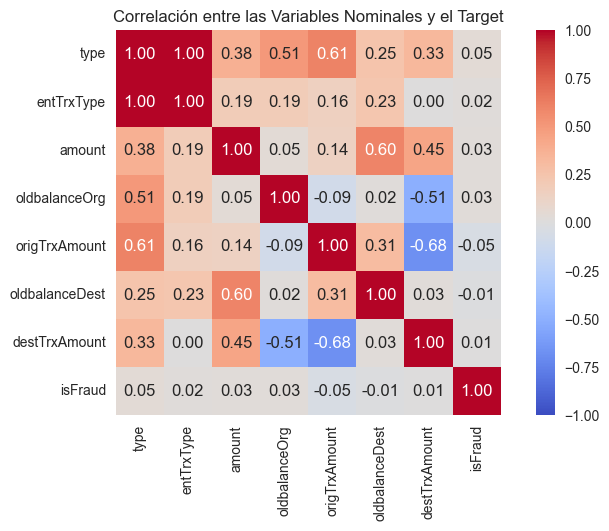

In [8]:
assoc = associations(df_train[cols_total+[target]],
    nominal_columns=cols_cat,
    numerical_columns=cols_num+[target],
    plot=True,num_num_assoc='spearman',nom_num_assoc='correlation_ratio',nom_nom_assoc='cramer',
    nan_strategy='drop_sample_pairs',
    cmap='coolwarm',title='Correlación entre las Variables Nominales y el Target',figsize=(9,5))

In [9]:
# type correlaciona mejor con isFraud que entTrxType
# Se considerara el resto de variables a pesar de que correlacionen hasta 68%

In [10]:
cols_total.remove('entTrxType')
cols_cat.remove('entTrxType')

### 2.2. RFE

In [11]:
X = df_train[cols_total]
y = df_train[target]
X.shape

(4629620, 6)

In [12]:
for col in cols_cat:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col])

In [13]:
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, stratify=y, random_state=666)

In [14]:
from catboost import CatBoostClassifier

model = CatBoostClassifier(random_state=666, verbose=0, allow_writing_files=False)
list_num_var = list(range(1, X_train.shape[1] + 1))

with sbp.MedirTiempoEjecucion():
    df_rfe = sbp.eliminacion_recursiva_de_variables(
        X_train, y_train, model, list_num_var, umbral=0.5, X_val=X_val, y_val=y_val,
        experiment_name="rfe_catboost", run_name="RFE catboost", tracking_uri=MLRUNS_DIR)

2026/10/07 21:06:18 INFO mlflow.tracking.fluent: Experiment with name 'rfe_catboost' does not exist. Creating a new experiment.


  0%|          | 0/5 [00:00<?, ?it/s]

2026/10/07 21:24:42 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
2026/10/07 21:43:05 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
2026/10/07 22:05:02 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
2026/10/07 22:31:37 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
2026/10/07 23:01:49 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


Número de variables seleccionadas: 1

Variables seleccionadas: ['amount']


,Num_Variables,Var_Eliminada,Train_AUC,Train_PR_AUC,Train_Accuracy,Train_F1,Train_Precision,Train_Recall,Train_Gini,Train_KS,Val_AUC,Val_PR_AUC,Val_Accuracy,Val_F1,Val_Precision,Val_Recall,Val_Gini,Val_KS
0,1,oldbalanceOrg,0.818476,0.010148,0.999227,0.000000,0.000000,0.000000,0.636952,0.457607,0.785313,0.009245,0.999227,0.000000,0.000000,0.000000,0.570627,0.419321
1,2,origTrxAmount,0.999230,0.683713,0.999505,0.569686,0.867143,0.424179,0.998461,0.988209,0.996322,0.629971,0.999478,0.554839,0.815718,0.420391,0.992644,0.980095
2,3,destTrxAmount,0.999368,0.746095,0.999531,0.618022,0.832938,0.491265,0.998737,0.988982,0.996509,0.686931,0.999474,0.577624,0.762014,0.465084,0.993017,0.982583
3,4,oldbalanceDest,0.999792,0.921311,0.999764,0.826243,0.958487,0.726066,0.999584,0.992494,0.996807,0.854289,0.999714,0.791174,0.907776,0.701117,0.993613,0.984139
4,5,type,0.999963,0.971554,0.999844,0.890114,0.976230,0.817959,0.999926,0.997172,0.997584,0.835623,0.999706,0.790769,0.880137,0.717877,0.995167,0.984141


Tiempo transcurrido: 1 horas, 55 minutos y 31.080 segundos


In [ ]:
# El modelo con 5 variables obtiene Val_F1_Score de 0.790769
# El modelo con 4 variables obtiene Val_F1_Score de 0.791174 pero con menos val_recall
# >>> Nos quedamos con las 5 variables.

---

## 3. Optimizacion

In [14]:
print("Features:", cols_total)

Features: ['type', 'amount', 'oldbalanceOrg', 'origTrxAmount', 'oldbalanceDest', 'destTrxAmount']


In [15]:
print(f"Hilos Lógicos: ",psutil.cpu_count(logical=True))
print(f"Núcleos físicos: ",psutil.cpu_count(logical=False))

Hilos Lógicos:  16
Núcleos físicos:  12


### Estudio 1

In [18]:
seed_vf = 666

def construir_params(trial, ratio_desbalance, cat_features=None):
    params = dict(
        # Fijos
        loss_function='Logloss', random_seed=seed_vf, thread_count=8,
        verbose=0, allow_writing_files=False,
        # Variables
        iterations       = trial.suggest_int('iterations', 500, 1500),
        learning_rate    = trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        depth            = trial.suggest_int('depth', 4, 10),
        l2_leaf_reg      = trial.suggest_float('l2_leaf_reg', 1, 50, log=True),
        random_strength  = trial.suggest_float('random_strength', 0.1, 10, log=True),
        rsm              = trial.suggest_float('rsm', 0.5, 1.0),
        border_count     = trial.suggest_categorical('border_count', [64, 128, 254]),
        scale_pos_weight = trial.suggest_float('scale_pos_weight', 1, ratio_desbalance, log=True),
    )
    # Bootstrap
    bootstrap = trial.suggest_categorical('bootstrap_type', ['Bernoulli', 'Bayesian'])
    params['bootstrap_type'] = bootstrap
    if bootstrap == 'Bernoulli':
        params['subsample'] = trial.suggest_float('subsample', 0.5, 1.0)
    else:
        params['bagging_temperature'] = trial.suggest_float('bagging_temperature', 0.0, 10.0)

    # Variables categoricas
    if cat_features:
        params['cat_features'] = cat_features
        params['max_ctr_complexity'] = trial.suggest_int('max_ctr_complexity', 1, 4)
        params['one_hot_max_size']   = trial.suggest_categorical('one_hot_max_size', [2, 10, 25])
    
    return params


def cv_catboost_con_pruning(trial, X, y, params, n_splits=5, umbral=0.5, random_state=seed_vf):
    y = np.asarray(y)
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    scores, met_folds = [], []

    for fold, (i_tr, i_va) in enumerate(skf.split(X, y)):
        model = CatBoostClassifier(**params)
        model.fit(X.iloc[i_tr], y[i_tr])

        met = sbp.metricas_clasificacion_binaria(y[i_va], model.predict_proba(X.iloc[i_va])[:, 1], umbral)
        met_folds.append(met)
        scores.append(met["PR_AUC"]) # metrica

        if mlflow.active_run():
            mlflow.log_metrics({f"fold_{k}": v for k, v in met.items() if np.isfinite(v)}, step=fold)

        media_parcial = float(np.nanmean(scores))
        if np.isfinite(media_parcial):
            trial.report(media_parcial, step=fold)
            if trial.should_prune():
                raise optuna.TrialPruned()

    return scores, met_folds


def optimizar_catboost_optuna(X, y, experiment_name,
                              study_name="CATB_fraude_prauc", n_trials=50,
                              cat_features=None, X_val=None, y_val=None,
                              n_splits=5, umbral=0.5, run_name="Optuna CatBoost",
                              db_name="estudio_catboost_fraude.db"):

    # MLflow
    mlflow.set_tracking_uri(MLRUNS_DIR)
    mlflow.set_experiment(experiment_name)

    ratio = float((np.asarray(y) == 0).sum() / (np.asarray(y) == 1).sum())

    def objetivo(trial):
        params = construir_params(trial, ratio, cat_features)
        podado = False
        with mlflow.start_run(run_name=f"trial_{trial.number}", nested=True):
            mlflow.log_params(trial.params)
            try:
                scores, met_folds = cv_catboost_con_pruning(trial, X, y, params, n_splits, umbral)
            except optuna.TrialPruned:
                mlflow.set_tag("estado", "PRUNED")
                podado = True
            else:
                mlflow.set_tag("estado", "COMPLETE")
                resumen = {}
                for k in met_folds[0].keys():
                    vals = [m[k] for m in met_folds]
                    resumen[f"cv_{k}_mean"] = float(np.nanmean(vals))
                    resumen[f"cv_{k}_std"] = float(np.nanstd(vals))
                mlflow.log_metrics({k: v for k, v in resumen.items() if np.isfinite(v)})
                trial.set_user_attr("scores_cross_val", scores)
                trial.set_user_attr("metricas_cv", resumen)
        if podado:
            raise optuna.TrialPruned()
        return float(np.nanmean(scores))

    estudio = optuna.create_study(
        direction="maximize",
        study_name=study_name,
        storage=f"sqlite:///{OPTUNA_DIR+db_name}",
        load_if_exists=True,
        pruner=optuna.pruners.MedianPruner(n_startup_trials=15, n_warmup_steps=1, interval_steps=1),
        sampler=optuna.samplers.TPESampler(seed=seed_vf),
    )

    with mlflow.start_run(run_name=run_name):  # run padre
        mlflow.log_params({"n_trials": n_trials, "n_splits": n_splits, "seed": seed_vf,
                           "metrica_optimizada": "PR-AUC", "umbral": umbral,
                           "ratio_desbalance": round(ratio, 1), "study_name": study_name})

        estudio.optimize(objetivo, n_trials=n_trials, n_jobs=1)

        # Mejor trial
        best = estudio.best_trial
        mlflow.log_metric("best_pr_auc_cv", best.value)
        mlflow.log_dict(best.params, "mejores_hiperparametros.json")
        mlflow.log_text(estudio.trials_dataframe().to_csv(index=False), "trials.csv")

        # Reentrenar el mejor modelo con todos los datos
        best_params = construir_params(optuna.trial.FixedTrial(best.params), ratio, cat_features)
        modelo_final = CatBoostClassifier(**best_params).fit(X, y)

        # Metricas de CV del trial ganador
        mlflow.log_metrics({f"best_{k}": v for k, v in best.user_attrs.get("metricas_cv", {}).items()
                            if np.isfinite(v)})

        # Metricas del modelo final: train y validacion
        met_train = sbp.metricas_clasificacion_binaria(y, modelo_final.predict_proba(X)[:, 1], umbral)
        mlflow.log_metrics({f"train_{k}": v for k, v in met_train.items() if np.isfinite(v)})

        if X_val is not None:
            met_val = sbp.metricas_clasificacion_binaria(y_val, modelo_final.predict_proba(X_val)[:, 1], umbral)
            mlflow.log_metrics({f"val_{k}": v for k, v in met_val.items() if np.isfinite(v)})

        mlflow.catboost.log_model(modelo_final, artifact_path="model")

    print(f"\nMejor trial {best.number}: PR-AUC CV = {best.value:.4f}")
    print(best.params)
    
    return estudio, modelo_final

In [19]:
estudio, modelo_final = optimizar_catboost_optuna(
    X_train, y_train, experiment_name="optuna_catboost_fraude",
    n_trials=50, cat_features=None, X_val=X_val, y_val=y_val, umbral=0.5, db_name="estudio_catboost_fraude.db")

[I 2026-10-08 00:00:07,752] A new study created in RDB with name: CATB_fraude_prauc
[I 2026-10-08 00:36:07,032] Trial 0 finished with value: 0.8080250446984086 and parameters: {'iterations': 1201, 'learning_rate': 0.12540421798589482, 'depth': 8, 'l2_leaf_reg': 17.242848273004956, 'random_strength': 7.996794115960455, 'rsm': 0.5063515985173839, 'border_count': 64, 'scale_pos_weight': 38.099067555096205, 'bootstrap_type': 'Bayesian', 'bagging_temperature': 1.9289200304058374}. Best is trial 0 with value: 0.8080250446984086.
[I 2026-10-08 01:19:46,866] Trial 1 finished with value: 0.8406262049742239 and parameters: {'iterations': 1201, 'learning_rate': 0.0240712454492742, 'depth': 9, 'l2_leaf_reg': 1.0201869499588057, 'random_strength': 0.16815713804621452, 'rsm': 0.5554768359937233, 'border_count': 254, 'scale_pos_weight': 11.43043920858065, 'bootstrap_type': 'Bayesian', 'bagging_temperature': 9.783469850151286}. Best is trial 1 with value: 0.8406262049742239.
[I 2026-10-08 01:52:00,819


Mejor trial 40: PR-AUC CV = 0.8690
{'iterations': 1195, 'learning_rate': 0.04862830951101363, 'depth': 7, 'l2_leaf_reg': 1.451940770223384, 'random_strength': 0.10049358234425926, 'rsm': 0.7275251958270231, 'border_count': 254, 'scale_pos_weight': 17.71668095991105, 'bootstrap_type': 'Bernoulli', 'subsample': 0.5713279770612507}


In [21]:
# ver en dashboard: uv run optuna-dashboard sqlite:///estudio_catboost_fraude.db

### Estudio 2: parametros ajustados

In [33]:
def construir_params(trial, ratio_desbalance, cat_features=None):
    params = dict(
        # Fijos
        loss_function='Logloss', random_seed=seed_vf, thread_count=8,
        verbose=0, allow_writing_files=False,
        # Nuevos Fijos
        bootstrap_type   = 'Bernoulli',
        border_count     = 254,
        # Rangos ajustados
        iterations       = trial.suggest_int('iterations', 900, 1300),
        learning_rate    = trial.suggest_float('learning_rate', 0.01, 0.1),
        depth            = trial.suggest_int('depth', 6, 9),
        l2_leaf_reg      = trial.suggest_float('l2_leaf_reg', 1, 3),
        random_strength  = trial.suggest_float('random_strength', 0.1, 0.5),
        rsm              = trial.suggest_float('rsm', 0.55, 1.0),
        scale_pos_weight = trial.suggest_float('scale_pos_weight', 1, ratio_desbalance, log=True),
        subsample        = trial.suggest_float('subsample', 0.5, 1.0),
    )
    
    # Variables categoricas
    if cat_features:
        params['cat_features'] = cat_features
        params['max_ctr_complexity'] = trial.suggest_int('max_ctr_complexity', 1, 4)
        params['one_hot_max_size']   = trial.suggest_categorical('one_hot_max_size', [2, 10, 25])
    
    return params

In [ ]:
estudio, modelo_final = optimizar_catboost_optuna(
    X_train, y_train, experiment_name="optuna_catboost_fraude2",
    n_trials=50, cat_features=cols_cat, X_val=X_val, y_val=y_val, umbral=0.5, db_name="estudio_catboost_fraude2.db")

2026/10/09 08:53:27 INFO mlflow.tracking.fluent: Experiment with name 'optuna_catboost_fraude2' does not exist. Creating a new experiment.
[I 2026-10-09 08:53:27,556] A new study created in RDB with name: CATB_fraude_prauc


Métricas de la validación cruzada

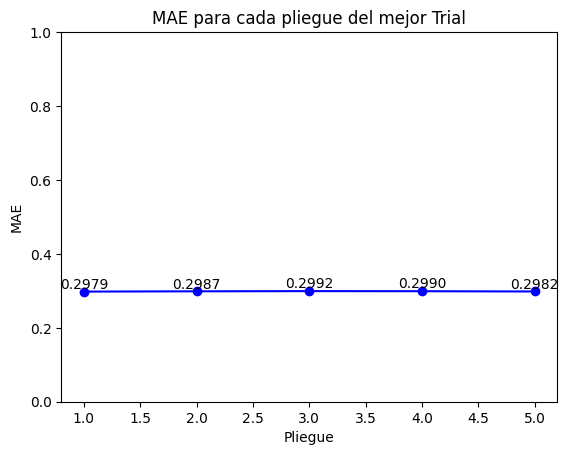

In [91]:
df_optuna = estudio.trials_dataframe()  # Dataframe de toda la optimización
scores = df_optuna[df_optuna['number']==374][['user_attrs_scores_cross_val']].values[0][0]

plt.plot(range(1, 6), scores, marker='o', linestyle='-', color='b')
plt.xlabel('Pliegue')
plt.ylabel('MAE')
plt.title(f'MAE para cada pliegue del mejor Trial')
plt.ylim(0,1)
for i, score in enumerate(scores):
    plt.text(i + 1, score, f'{score:.4f}', ha='center', va='bottom')
plt.show()

##### Etapa 2: Optimización de Pesos

In [93]:
X_train = df_train[features_rfe_best]
y_train = df_train['INGRESO_CAP_V2_LOG']

In [ ]:
best_hiperparams = estudio.best_trial.params

In [94]:
gbm = lgb.LGBMRegressor(**best_hiperparams)
gbm.fit(X_train, y_train, categorical_feature=features_rfe_cat)

LGBMRegressor(bagging_fraction=0.9388581044106404, bagging_freq=1,
              bagging_seed=112233, cat_l2=25.946075566589915,
              cat_smooth=120.29574924651835, fair_c=0.21526017439314066,
              feature_fraction=0.736842105, feature_fraction_seed=112233,
              lambda_l1=3.674279086051664, lambda_l2=6.170354116507608,
              learning_rate=0.06282868072404353, max_cat_threshold=32,
              max_depth=16, metric='l1', min_data_in_leaf=218,
              min_gain_to_split=1.1851155536870793e-05,
              min_sum_hessian_in_leaf=0.001779022974407748, num_iterations=1374,
              num_leaves=116, num_threads=8, objective='fair', seed=112233,
              verbose=-1)

Para la frecuencia de los pesos

In [95]:
X_train = df_train[features_rfe_best]
y_train = df_train['INGRESO_CAP_V2_LOG']

X_test = df_test[features_rfe_best]
y_test = df_test['INGRESO_CAP_V2_LOG']   

y_pred_train = np.exp(gbm.predict(X_train))
y_real_train = np.exp(y_train)

y_pred_test = np.exp(gbm.predict(X_test))
y_real_test = np.exp(y_test)

In [96]:
sbp.calcular_coincidencia(y_pred_train,y_pred_test,y_real_train,y_real_test,0.3)

,Subestimacion,Coincidencia,Sobreestimacion
Train,0.150823,0.662813,0.186364
Test,0.174005,0.609371,0.216624


Train

In [97]:
bins = [999,1500,2000,3500,5000,7000,10000,12500,15000,float("inf")]
sbp.calcular_precision_x_intervalos(y_pred_train,y_real_train,0.3,bins)

,Casos,Casos (%),Prom. real,Prom. pred,Subestimacion,Coincidencia,Sobreestimacion
Intervalos,,,,,,,
"(999.0, 1500.0]",113872,0.223630,1252.576898,1704.664422,0.000000,0.500940,0.499060
"(1500.0, 2000.0]",96720,0.189946,1733.457359,1893.852310,0.002709,0.847911,0.149380
"(2000.0, 3500.0]",152741,0.299964,2662.423505,2524.503125,0.171179,0.739723,0.089099
"(3500.0, 5000.0]",56385,0.110733,4157.680046,3619.795313,0.325086,0.592179,0.082735
"(5000.0, 7000.0]",38044,0.074714,5866.302467,5093.638583,0.311771,0.611870,0.076359
"(7000.0, 10000.0]",24709,0.048525,8280.304309,6890.866290,0.331701,0.608685,0.059614
"(10000.0, 12500.0]",10038,0.019713,11113.055433,8860.852233,0.367902,0.582686,0.049412
"(12500.0, 15000.0]",5420,0.010644,13622.778051,10515.990635,0.411255,0.545203,0.043542
"(15000.0, inf]",11269,0.022131,23614.508336,15285.517836,0.539711,0.439436,0.020854


In [98]:
bins = [999,1500,3500,15000,float("inf")]
sbp.calcular_precision_x_intervalos(y_pred_train,y_real_train,0.3,bins)

,Casos,Casos (%),Prom. real,Prom. pred,Subestimacion,Coincidencia,Sobreestimacion
Intervalos,,,,,,,
"(999.0, 1500.0]",113872,0.223630,1252.576898,1704.664422,0.000000,0.500940,0.499060
"(1500.0, 3500.0]",249461,0.489910,2302.248545,2279.989767,0.105860,0.781669,0.112470
"(3500.0, 15000.0]",134596,0.264329,6297.324936,5305.453833,0.329200,0.598175,0.072625
"(15000.0, inf]",11269,0.022131,23614.508336,15285.517836,0.539711,0.439436,0.020854


Test

In [100]:
bins = [999,1500,2000,3500,5000,7000,10000,12500,15000,float("inf")]
sbp.calcular_precision_x_intervalos(y_pred_test,y_real_test,0.3,bins)

,Casos,Casos (%),Prom. real,Prom. pred,Subestimacion,Coincidencia,Sobreestimacion
Intervalos,,,,,,,
"(999.0, 1500.0]",28344,0.223288,1252.380137,1745.247051,0.000000,0.463625,0.536375
"(1500.0, 2000.0]",24017,0.189201,1734.909069,1937.848750,0.004372,0.813840,0.181788
"(2000.0, 3500.0]",38171,0.300703,2658.105261,2546.500620,0.193314,0.693118,0.113568
"(3500.0, 5000.0]",14076,0.110888,4156.552513,3635.450015,0.366368,0.516624,0.117008
"(5000.0, 7000.0]",9424,0.074240,5862.502980,5069.183638,0.360569,0.532258,0.107173
"(7000.0, 10000.0]",6170,0.048606,8274.115196,6838.344287,0.391734,0.512156,0.096110
"(10000.0, 12500.0]",2503,0.019718,11121.300750,8572.218291,0.449860,0.485018,0.065122
"(12500.0, 15000.0]",1364,0.010745,13644.387702,9814.080467,0.538856,0.398827,0.062317
"(15000.0, inf]",2870,0.022609,24039.073012,14755.237508,0.617073,0.349477,0.033449


In [101]:
bins = [999,1500,3500,15000,float("inf")]
sbp.calcular_precision_x_intervalos(y_pred_test,y_real_test,0.3,bins)

,Casos,Casos (%),Prom. real,Prom. pred,Subestimacion,Coincidencia,Sobreestimacion
Intervalos,,,,,,,
"(999.0, 1500.0]",28344,0.223288,1252.380137,1745.247051,0.000000,0.463625,0.536375
"(1500.0, 3500.0]",62188,0.489905,2301.566975,2311.439323,0.120345,0.739741,0.139914
"(3500.0, 15000.0]",33537,0.264198,6299.153550,5247.333793,0.382652,0.513045,0.104303
"(15000.0, inf]",2870,0.022609,24039.073012,14755.237508,0.617073,0.349477,0.033449


Optimización multiobjetivo

In [102]:
seed_vf1 = 223344

In [104]:
def objective(trial):
    a = trial.suggest_float('a', 10, 25, step=0.005)
    b = trial.suggest_float('b', 1, 10, step=0.005)

    name = f"W_a={a:.4f}_b={b:.4f}"
    trial.set_user_attr("weight_name", name)

    kf = KFold(n_splits=5, shuffle=True, random_state=seed_vf1)

    coinc_list, sobre_list, coinc_low_list, coinc_upp_list = [], [], [], []

    for train_idx, val_idx in kf.split(X_train):
        X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

        weights = df_train['INGRESO_CAP_V2'].iloc[train_idx].apply(lambda x: assign_weights_v2(x, a, b))

        coinc, sobre, coinc_low, coinc_upp = calcular_prec_pesos_con_CV(
            X_tr, y_tr, X_val, y_val, features_rfe_cat, best_hiperparams, weights
        )

        coinc_list.append(coinc)
        sobre_list.append(sobre)
        coinc_low_list.append(coinc_low)
        coinc_upp_list.append(coinc_upp)

    
    # Registrar métricas por fold
    trial.set_user_attr("coinc_por_fold", coinc_list)
    trial.set_user_attr("sobre_por_fold", sobre_list)
    trial.set_user_attr("coinc_low_por_fold", coinc_low_list)
    trial.set_user_attr("coinc_upp_por_fold", coinc_upp_list)


    # Promediar métricas
    return (
        np.mean(coinc_list),
        np.mean(sobre_list),
        np.mean(coinc_low_list),
        np.mean(coinc_upp_list)
    )

# Ejecutar la optimización
study = optuna.create_study(
    directions=["maximize","minimize","maximize","maximize"],
    study_name="Opt_Pesos_20var",
    storage="sqlite:///Mi_estudio_VF.db" ,
    sampler=NSGAIISampler(seed=seed_vf1)
    )    
study.optimize(objective, n_trials=300)

# Acceder al frente de Pareto
for trial in study.best_trials:
    name = trial.user_attrs["weight_name"]
    print(f"Trial {trial.number} - {name} - Coinc: {trial.values[0]:.4f}, Sobre: {trial.values[1]:.4f}, Coinc_Low: {trial.values[2]:.4f}, Coinc_Upp: {trial.values[3]:.4f}")

[I 2026-01-02 09:24:44,699] A new study created in RDB with name: Opt_Pesos_20var
[I 2026-01-02 09:31:03,888] Trial 0 finished with values: [0.6189831808632339, 0.13778333902224654, 0.8013650892256126, 0.3964283431913419] and parameters: {'a': 21.045, 'b': 6.545}.
[I 2026-01-02 09:37:15,913] Trial 1 finished with values: [0.6251261772631318, 0.16475909273549755, 0.6773942194283308, 0.36772954499492294] and parameters: {'a': 12.645, 'b': 8.465}.
[I 2026-01-02 09:43:32,450] Trial 2 finished with values: [0.6257173014423433, 0.15824689170398323, 0.7053320473293072, 0.3773841023586565] and parameters: {'a': 14.379999999999999, 'b': 7.640000000000001}.
[I 2026-01-02 09:49:43,939] Trial 3 finished with values: [0.6250004893126171, 0.16872022280875282, 0.6616642382020765, 0.3701106454313815] and parameters: {'a': 11.355, 'b': 6.035}.
[I 2026-01-02 09:56:01,725] Trial 4 finished with values: [0.6251301044722355, 0.16158743819771834, 0.6970067153427524, 0.38138606280700343] and parameters: {'a'

Trial 0 - W_a=21.0450_b=6.5450 - Coinc: 0.6190, Sobre: 0.1378, Coinc_Low: 0.8014, Coinc_Upp: 0.3964
Trial 2 - W_a=14.3800_b=7.6400 - Coinc: 0.6257, Sobre: 0.1582, Coinc_Low: 0.7053, Coinc_Upp: 0.3774
Trial 7 - W_a=18.8500_b=8.1750 - Coinc: 0.6233, Sobre: 0.1442, Coinc_Low: 0.7675, Coinc_Upp: 0.3891
Trial 9 - W_a=22.6550_b=4.7100 - Coinc: 0.6134, Sobre: 0.1330, Coinc_Low: 0.8330, Coinc_Upp: 0.4086
Trial 10 - W_a=15.7300_b=3.4600 - Coinc: 0.6236, Sobre: 0.1511, Coinc_Low: 0.7473, Coinc_Upp: 0.3925
Trial 13 - W_a=23.2700_b=7.1250 - Coinc: 0.6151, Sobre: 0.1324, Coinc_Low: 0.8276, Coinc_Upp: 0.4007
Trial 14 - W_a=20.1000_b=5.7150 - Coinc: 0.6203, Sobre: 0.1398, Coinc_Low: 0.7929, Coinc_Upp: 0.3975
Trial 17 - W_a=19.9800_b=5.9650 - Coinc: 0.6207, Sobre: 0.1403, Coinc_Low: 0.7902, Coinc_Upp: 0.3946
Trial 18 - W_a=19.9050_b=6.5800 - Coinc: 0.6213, Sobre: 0.1407, Coinc_Low: 0.7862, Coinc_Upp: 0.3941
Trial 20 - W_a=22.2550_b=8.6200 - Coinc: 0.6183, Sobre: 0.1354, Coinc_Low: 0.8102, Coinc_Upp: 0

In [105]:
df_optuna2 = study.trials_dataframe()  # Dataframe de toda la optimización

In [106]:
df_optuna2.to_csv("C:/Users/s2660778/The Bank of Nova Scotia/Gonzales Cornejo, Kevin Fausto - 023. Estimador_Ingresos_Cliente/Sprint 4/Single_Model_VF2/OPTUNA_results_Weights_Opt_vf.csv",index=False)

##### Etapa 3: Optimización con pesos

P3

In [ ]:
#weights_opt = df_train['INGRESO_CAP_V2'].apply(lambda x: assign_weights_v2(x, 15.3150, 9.920))

In [110]:
weights_opt = df_train['INGRESO_CAP_V2'].apply(lambda x: assign_weights_v2(x, 15.7400, 9.5000))

In [111]:
from lightgbm import LGBMRegressor

seed_vf = 556677

def objetivo(trial):
    model_fn = lambda trial: LGBMRegressor(
    
    # Hiperparámetros fijos
    objective                = trial.suggest_categorical('objective', ['fair']),
    metric                   = trial.suggest_categorical('metric', ['l1']),
    seed                     = trial.suggest_categorical('seed', [seed_vf]),
    feature_fraction_seed    = trial.suggest_categorical('feature_fraction_seed', [seed_vf]),
    bagging_seed             = trial.suggest_categorical('bagging_seed', [seed_vf]),
    bagging_freq             = trial.suggest_categorical('bagging_freq', [1]),
    verbose                  = trial.suggest_categorical('verbose', [-1]),
    num_threads              = trial.suggest_categorical('num_threads', [8]),
    max_cat_threshold        = trial.suggest_categorical("max_cat_threshold", [32,64,128,256,512]),
    categorical_feature      = ["UBIGEO_INMUEBLE","CARRERA"],
    fair_c                   = trial.suggest_categorical("fair_c",[0.21526017439314066]),
    
    # Hiperparámetros variables
    num_leaves               = trial.suggest_int('num_leaves', 50, 130),
    max_depth                = trial.suggest_int('max_depth', 5, 20),
    num_iterations           = trial.suggest_int('num_iterations', 1000, 1500),  # 500-1500
    min_data_in_leaf         = trial.suggest_int('min_data_in_leaf', 1000, 2000),    # 100-2000
    min_sum_hessian_in_leaf  = trial.suggest_float('min_sum_hessian_in_leaf', 1e-4, 1e-1, log=True),
    learning_rate            = trial.suggest_float('learning_rate', 0.01, 0.07, log=True),   # 0.01-0.1
    feature_fraction         = trial.suggest_float('feature_fraction', 0.421052632, 0.684210527, step=0.052631579),    # 0.736842105, 0.8947368419
    bagging_fraction         = trial.suggest_float('bagging_fraction', 0.70, 0.95),
    lambda_l1                = trial.suggest_float('lambda_l1', 5, 10), # 1-10
    lambda_l2                = trial.suggest_float('lambda_l2', 5, 10), # 1-10
    min_gain_to_split        = trial.suggest_float("min_gain_to_split", 1e-3, 1.0, log=True),   # 1e-5 - 1.0
    cat_l2                   = trial.suggest_float('cat_l2', 100, 300, log=True),
    cat_smooth               = trial.suggest_float('cat_smooth', 100, 300, log=True)
    )

    scores = cross_val_with_pruning_sw(trial, X, y, model_fn, n_splits=5, random_state=seed_vf, sample_weight=weights_opt)
    trial.set_user_attr("scores_cross_val", scores)
    
    return np.mean(scores) 

# Crear el estudio con MedianPruner
estudio = optuna.create_study(
    direction="minimize",
    study_name="LGBM_log_20var_con_pesos_v3",
    storage="sqlite:///Mi_estudio_VF.db",
    load_if_exists=True,
    pruner=optuna.pruners.MedianPruner(n_startup_trials=25, n_warmup_steps=20, interval_steps=20),
    sampler=optuna.samplers.TPESampler(seed=seed_vf)
)

estudio.optimize(objetivo, n_trials=300, n_jobs=1)  # 200

# Mostrar mejores resultados
print('\nMejores hiperparámetros: \n')
best_trial = estudio.best_trial
print(f'Trial {best_trial.number}: {best_trial.params}, Score: {best_trial.value}')

[I 2026-01-03 15:00:18,671] A new study created in RDB with name: LGBM_log_20var_con_pesos_v3
[I 2026-01-03 15:03:11,127] Trial 0 finished with value: 0.32002109845629073 and parameters: {'objective': 'fair', 'metric': 'l1', 'seed': 556677, 'feature_fraction_seed': 556677, 'bagging_seed': 556677, 'bagging_freq': 1, 'verbose': -1, 'num_threads': 8, 'max_cat_threshold': 256, 'fair_c': 0.21526017439314066, 'num_leaves': 71, 'max_depth': 6, 'num_iterations': 1461, 'min_data_in_leaf': 1775, 'min_sum_hessian_in_leaf': 0.011077203708683061, 'learning_rate': 0.02600468057119894, 'feature_fraction': 0.52631579, 'bagging_fraction': 0.8537065828675234, 'lambda_l1': 6.668000194462413, 'lambda_l2': 6.829431201336275, 'min_gain_to_split': 0.4664291171334908, 'cat_l2': 110.20219408876052, 'cat_smooth': 101.73891673276823}. Best is trial 0 with value: 0.32002109845629073.
[I 2026-01-03 15:15:28,951] Trial 1 finished with value: 0.3152161278982204 and parameters: {'objective': 'fair', 'metric': 'l1', '


Mejores hiperparámetros: 

Trial 297: {'objective': 'fair', 'metric': 'l1', 'seed': 556677, 'feature_fraction_seed': 556677, 'bagging_seed': 556677, 'bagging_freq': 1, 'verbose': -1, 'num_threads': 8, 'max_cat_threshold': 32, 'fair_c': 0.21526017439314066, 'num_leaves': 67, 'max_depth': 15, 'num_iterations': 1179, 'min_data_in_leaf': 1593, 'min_sum_hessian_in_leaf': 0.0018423835049835725, 'learning_rate': 0.06728144452071953, 'feature_fraction': 0.631578948, 'bagging_fraction': 0.8386402984248987, 'lambda_l1': 5.193104776130206, 'lambda_l2': 6.28828843221193, 'min_gain_to_split': 0.0011416195438248343, 'cat_l2': 100.09747692408972, 'cat_smooth': 104.40744132976026}, Score: 0.3116924218088096


Métricas de la validación cruzada

In [113]:
df_optuna3 = estudio.trials_dataframe()

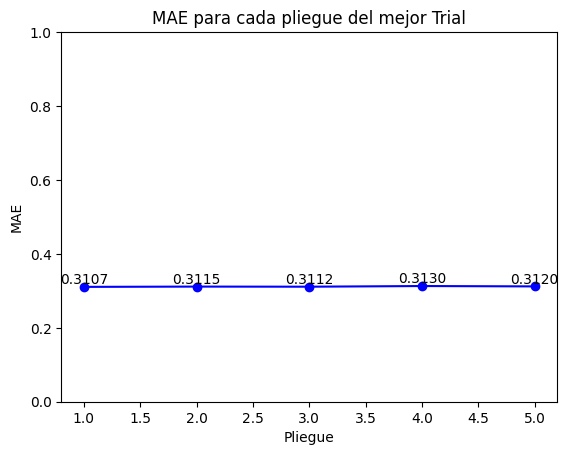

In [114]:
scores = df_optuna3[df_optuna3['number']==297][['user_attrs_scores_cross_val']].values[0][0]

plt.plot(range(1, 6), scores, marker='o', linestyle='-', color='b')
plt.xlabel('Pliegue')
plt.ylabel('MAE')
plt.title(f'MAE para cada pliegue del mejor Trial')
plt.ylim(0,1)
for i, score in enumerate(scores):
    plt.text(i + 1, score, f'{score:.4f}', ha='center', va='bottom')
plt.show()

In [115]:
df_optuna3.to_csv("C:/Users/s2660778/The Bank of Nova Scotia/Gonzales Cornejo, Kevin Fausto - 023. Estimador_Ingresos_Cliente/Sprint 4/Single_Model_VF2/OPTUNA_results_S4_Con_Pesos_vf3.csv",index=False)

#### 4.2.2.Gráficos OPTUNA

##### Etapa 1

In [85]:
from optuna.visualization import plot_optimization_history

plotly_config = {"staticPlot": True}

fig = plot_optimization_history(estudio)
fig.show(config=plotly_config)

#plot_optimization_history(estudio)

In [86]:
optuna.visualization.plot_param_importances(estudio)

In [87]:
optuna.visualization.plot_parallel_coordinate(estudio)

In [88]:
optuna.visualization.plot_slice(estudio)

In [89]:
from optuna.visualization import (
    plot_optimization_history,
    plot_param_importances,
    plot_parallel_coordinate,
    plot_slice
)

# estudio = optuna.load_study(study_name="LGBM_log_20var_sin_pesos", storage="sqlite:///Mi_estudio_vf.db")

# Generar gráficos
fig1 = plot_optimization_history(estudio)
fig2 = plot_param_importances(estudio)
fig3 = plot_parallel_coordinate(estudio)
fig4 = plot_slice(estudio)

# Crear HTML con todos los gráficos
html_content = f"""
<html>
<head>
<title>Optuna Optimization Dashboard</title>
</head>
<body>
<h1>Optuna Optimization Dashboard</h1>
<h2>Optimization History</h2>
{fig1.to_html(full_html=False, include_plotlyjs='cdn')}
<h2>Parameter Importances</h2>
{fig2.to_html(full_html=False, include_plotlyjs=False)}
<h2>Parallel Coordinate</h2>
{fig3.to_html(full_html=False, include_plotlyjs=False)}
<h2>Slice Plot</h2>
{fig4.to_html(full_html=False, include_plotlyjs=False)}
</body>
</html>
"""

# Guardar en archivo
with open("optuna_dashboard_Sin_Pesos.html", "w", encoding="utf-8") as f:
    f.write(html_content)

print("Archivo HTML generado: optuna_dashboard_Sin_Pesos.html")

Archivo HTML generado: optuna_dashboard_Sin_Pesos.html


##### Etapa 2 

In [ ]:
import optuna
import optuna.visualization

optuna.visualization.plot_pareto_front(
    study, 
    targets=lambda trial: (trial.values[0], trial.values[1]), 
    target_names=["Coincidencia", "Sobreestimación"])

In [ ]:
optuna.visualization.plot_param_importances(
    study, 
    target=lambda trial: trial.values[0])

##### Etapa 3

In [116]:
from optuna.visualization import plot_optimization_history

plotly_config = {"staticPlot": True}

fig = plot_optimization_history(estudio)
fig.show(config=plotly_config)

#plot_optimization_history(estudio)

In [117]:
optuna.visualization.plot_param_importances(estudio)

In [118]:
optuna.visualization.plot_parallel_coordinate(estudio)

In [119]:
optuna.visualization.plot_slice(estudio)

P3

In [120]:
from optuna.visualization import (
    plot_optimization_history,
    plot_param_importances,
    plot_parallel_coordinate,
    plot_slice
)

# estudio = optuna.load_study(study_name="LGBM_log_20var_sin_pesos", storage="sqlite:///Mi_estudio_vf.db")

# Generar gráficos
fig1 = plot_optimization_history(estudio)
fig2 = plot_param_importances(estudio)
fig3 = plot_parallel_coordinate(estudio)
fig4 = plot_slice(estudio)

# Crear HTML con todos los gráficos
html_content = f"""
<html>
<head>
<title>Optuna Optimization Dashboard</title>
</head>
<body>
<h1>Optuna Optimization Dashboard</h1>
<h2>Optimization History</h2>
{fig1.to_html(full_html=False, include_plotlyjs='cdn')}
<h2>Parameter Importances</h2>
{fig2.to_html(full_html=False, include_plotlyjs=False)}
<h2>Parallel Coordinate</h2>
{fig3.to_html(full_html=False, include_plotlyjs=False)}
<h2>Slice Plot</h2>
{fig4.to_html(full_html=False, include_plotlyjs=False)}
</body>
</html>
"""

# Guardar en archivo
with open("optuna_dashboard_Con_Pesos_v3.html", "w", encoding="utf-8") as f:
    f.write(html_content)

print("Archivo HTML generado: optuna_dashboard_Con_Pesos_v3.html")

Archivo HTML generado: optuna_dashboard_Con_Pesos_v3.html


#### 4.2.3.Hiperparámetros 

Etapa 1

In [90]:
best_hiperparams = estudio.best_trial.params
#best_hiperparams.update({'boosting_type': 'gbdt', 'objective': 'fair','metric':'l1','random_state':567,'verbose':-1})
print(best_hiperparams)

{'objective': 'fair', 'metric': 'l1', 'seed': 112233, 'feature_fraction_seed': 112233, 'bagging_seed': 112233, 'bagging_freq': 1, 'verbose': -1, 'num_threads': 8, 'max_cat_threshold': 32, 'num_leaves': 116, 'max_depth': 16, 'num_iterations': 1374, 'min_data_in_leaf': 218, 'min_sum_hessian_in_leaf': 0.001779022974407748, 'learning_rate': 0.06282868072404353, 'feature_fraction': 0.736842105, 'bagging_fraction': 0.9388581044106404, 'lambda_l1': 3.674279086051664, 'lambda_l2': 6.170354116507608, 'min_gain_to_split': 1.1851155536870793e-05, 'cat_l2': 25.946075566589915, 'cat_smooth': 120.29574924651835, 'fair_c': 0.21526017439314066}


In [246]:
# 400 trials sin pesos / 19 var / fair
best_hiperparams = {'objective': 'fair', 'metric': 'l1', 'seed': 112233, 'feature_fraction_seed': 112233, 'bagging_seed': 112233, 'bagging_freq': 1, 'verbose': -1, 'num_threads': 8, 'max_cat_threshold': 32, 'num_leaves': 116, 'max_depth': 16, 'num_iterations': 1374, 'min_data_in_leaf': 218, 'min_sum_hessian_in_leaf': 0.001779022974407748, 'learning_rate': 0.06282868072404353, 'feature_fraction': 0.736842105, 'bagging_fraction': 0.9388581044106404, 'lambda_l1': 3.674279086051664, 'lambda_l2': 6.170354116507608, 'min_gain_to_split': 1.1851155536870793e-05, 'cat_l2': 25.946075566589915, 'cat_smooth': 120.29574924651835, 'fair_c': 0.21526017439314066}

Etapa 3

In [121]:
best_hiperparams = estudio.best_trial.params
print(best_hiperparams)

{'objective': 'fair', 'metric': 'l1', 'seed': 556677, 'feature_fraction_seed': 556677, 'bagging_seed': 556677, 'bagging_freq': 1, 'verbose': -1, 'num_threads': 8, 'max_cat_threshold': 32, 'fair_c': 0.21526017439314066, 'num_leaves': 67, 'max_depth': 15, 'num_iterations': 1179, 'min_data_in_leaf': 1593, 'min_sum_hessian_in_leaf': 0.0018423835049835725, 'learning_rate': 0.06728144452071953, 'feature_fraction': 0.631578948, 'bagging_fraction': 0.8386402984248987, 'lambda_l1': 5.193104776130206, 'lambda_l2': 6.28828843221193, 'min_gain_to_split': 0.0011416195438248343, 'cat_l2': 100.09747692408972, 'cat_smooth': 104.40744132976026}


P3

In [48]:
# 200 trials con pesos / 19 var / fair /
best_hiperparams = {'objective': 'fair', 'metric': 'l1', 'seed': 556677, 'feature_fraction_seed': 556677, 'bagging_seed': 556677, 'bagging_freq': 1, 'verbose': -1, 'num_threads': 8, 'max_cat_threshold': 32, 'fair_c': 0.21526017439314066, 'num_leaves': 67, 'max_depth': 15, 'num_iterations': 1179, 'min_data_in_leaf': 1593, 'min_sum_hessian_in_leaf': 0.0018423835049835725, 'learning_rate': 0.06728144452071953, 'feature_fraction': 0.631578948, 'bagging_fraction': 0.8386402984248987, 'lambda_l1': 5.193104776130206, 'lambda_l2': 6.28828843221193, 'min_gain_to_split': 0.0011416195438248343, 'cat_l2': 100.09747692408972, 'cat_smooth': 104.40744132976026}

---

#### 4.2.4.Entrenamiento

In [49]:
X_train = df_train[features_rfe_best]
y_train = df_train['INGRESO_CAP_V2_LOG']

X_test= df_test[features_rfe_best]
y_test = df_test['INGRESO_CAP_V2_LOG']

In [50]:
X_oot1 = df_oot1[features_rfe_best]
y_oot1 = df_oot1['INGRESO_CAP_V2_LOG']

X_oot2= df_oot2[features_rfe_best]
y_oot2 = df_oot2['INGRESO_CAP_V2_LOG']

X_oot3= df_oot3[features_rfe_best]
y_oot3 = df_oot3['INGRESO_CAP_V2_LOG']

pesos

In [51]:
weights_opt = df_train['INGRESO_CAP_V2'].apply(lambda x: assign_weights_v2(x, 15.7400, 9.5000))

In [52]:
gbm = lgb.LGBMRegressor(**best_hiperparams)

#gbm.fit(X_train, y_train, categorical_feature=features_rfe_cat)
gbm.fit(X_train, y_train, categorical_feature=features_rfe_cat, sample_weight=weights_opt)

LGBMRegressor(bagging_fraction=0.8386402984248987, bagging_freq=1,
              bagging_seed=556677, cat_l2=100.09747692408972,
              cat_smooth=104.40744132976026, fair_c=0.21526017439314066,
              feature_fraction=0.631578948, feature_fraction_seed=556677,
              lambda_l1=5.193104776130206, lambda_l2=6.28828843221193,
              learning_rate=0.06728144452071953, max_cat_threshold=32,
              max_depth=15, metric='l1', min_data_in_leaf=1593,
              min_gain_to_split=0.0011416195438248343,
              min_sum_hessian_in_leaf=0.0018423835049835725,
              num_iterations=1179, num_leaves=67, num_threads=8,
              objective='fair', seed=556677, verbose=-1)

In [251]:
# Guardar el modelo entrenado
#   joblib.dump(gbm, "C:/Users/s2660778/The Bank of Nova Scotia/Gonzales Cornejo, Kevin Fausto - 023. Estimador_Ingresos_Cliente/Sprint 4/Single_Model_VF2/MODEL_lgbm_Etapa_1.pkl")
joblib.dump(gbm, "C:/Users/s2660778/The Bank of Nova Scotia/Gonzales Cornejo, Kevin Fausto - 023. Estimador_Ingresos_Cliente/Sprint 4/Single_Model_VF2/MODEL_lgbm_Etapa_2.pkl")
#   joblib.dump(gbm, "C:/Users/s2660778/The Bank of Nova Scotia/Gonzales Cornejo, Kevin Fausto - 023. Estimador_Ingresos_Cliente/Sprint 4/Single_Model_VF2/MODEL_lgbm_Con_Pesos_Final_vf3.pkl")

['C:/Users/s2660778/The Bank of Nova Scotia/Gonzales Cornejo, Kevin Fausto - 023. Estimador_Ingresos_Cliente/Sprint 4/Single_Model_VF2/MODEL_lgbm_Etapa_2.pkl']

In [ ]:
#   Cargar el modelo entrenado
lgbm_model = joblib.load('C:/Users/s2660778/The Bank of Nova Scotia/Gonzales Cornejo, Kevin Fausto - 023. Estimador_Ingresos_Cliente/Sprint 4/Single_Model_VF2/MODEL_lgbm_Con_Pesos_Final_vf3.pkl')

In [53]:
sbp.importancias_lgbm_v2(gbm,X_train)

,Var,Split_Importance,Gain_Importance,Split_Weight,Gain_Weight,Avg_Weight,H_Avg_Weight
0,GHIGHESTBAL_NORM48,4604,15201.263187,0.093159,0.251503,0.172331,0.172423
1,MED_PAY_24M,3021,8048.648344,0.061128,0.133164,0.097146,0.106266
2,CARRERA,3549,4599.521312,0.071812,0.076099,0.073955,0.093712
3,MAX_CONSUMO_TOP4_60M,2927,4258.549230,0.059226,0.070457,0.064842,0.081616
4,MED_PASIVOS_IC_MIN6_12M,2372,3644.881956,0.047996,0.060304,0.054150,0.067787
5,MAX_MAX_LINCRE_TOP4_24M,2329,3566.517483,0.047126,0.059008,0.053067,0.066456
6,AVG_RED_CONSUMO_TOTAL_24M,2844,2781.882597,0.057546,0.046026,0.051786,0.064863
7,GAVGCCLIMIT1TO48,2692,2702.749663,0.054471,0.044717,0.049594,0.062287
8,MONTO_TRANSACCIONES_12M,2705,2358.874546,0.054734,0.039027,0.046881,0.057786
9,MAX_HIPOTECARIO_2010,1045,7547.780137,0.021145,0.124877,0.073011,0.045866


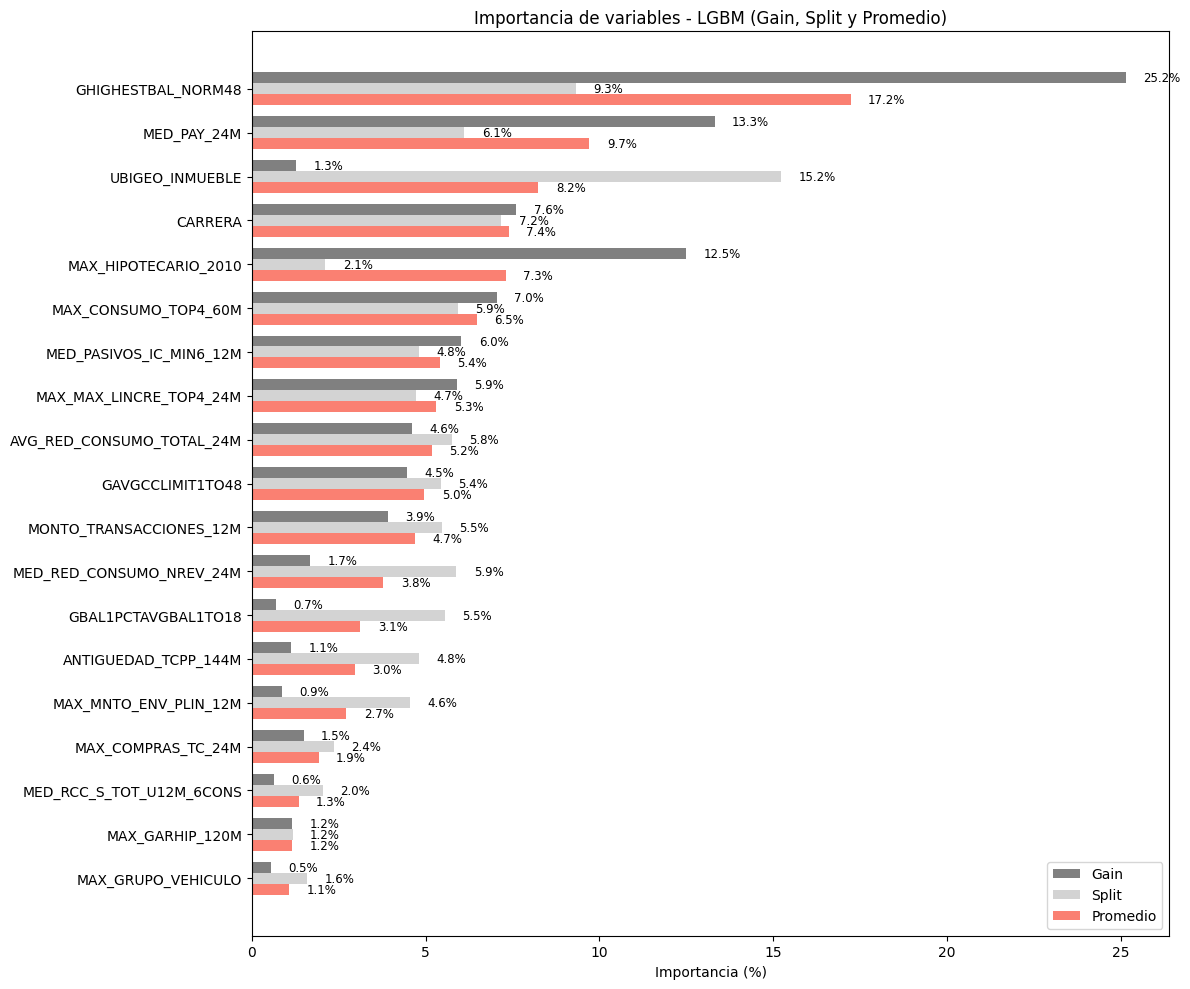

In [128]:
# Obtener importancias de tipo 'gain' y 'split'
gain_importance = gbm.booster_.feature_importance(importance_type='gain')
split_importance = gbm.booster_.feature_importance(importance_type='split')
feature_names = gbm.booster_.feature_name()

# Convertir a porcentaje
gain_importance_pct = 100 * gain_importance / np.sum(gain_importance)
split_importance_pct = 100 * split_importance / np.sum(split_importance)
average_importance_pct = (gain_importance_pct + split_importance_pct) / 2

# Crear una lista de tuplas con todas las importancias
importancias_combinadas = list(zip(feature_names, gain_importance_pct, split_importance_pct, average_importance_pct))

# Ordenar por la importancia promedio
importancias_combinadas.sort(key=lambda x: x[3], reverse=True)

# Separar los valores ordenados
nombres, gain_vals, split_vals, avg_vals = zip(*importancias_combinadas)

# Crear gráfico
plt.figure(figsize=(12, 10))
bar_width = 0.25
indices = np.arange(len(nombres))

bars1 = plt.barh(indices, gain_vals, bar_width, label='Gain', color='gray')
bars2 = plt.barh(indices + bar_width, split_vals, bar_width, label='Split', color='lightgray')
bars3 = plt.barh(indices + 2 * bar_width, avg_vals, bar_width, label='Promedio', color='salmon')

plt.xlabel("Importancia (%)")
plt.title("Importancia de variables - LGBM (Gain, Split y Promedio)")
plt.yticks(indices + bar_width, nombres)
plt.gca().invert_yaxis()
plt.legend()

# Agregar valores numéricos al final de cada barra
for bars in [bars1, bars2, bars3]:
    for bar in bars:
        plt.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
                f"{bar.get_width():.1f}%", va='center', fontsize = 8.5)

plt.tight_layout()
plt.show()


Para las métricas

In [54]:
y_pred_train = np.exp(gbm.predict(X_train))
y_pred_test = np.exp(gbm.predict(X_test))

y_real_train = df_train["INGRESO_CAP_V2"]
y_real_test = df_test["INGRESO_CAP_V2"]

y_pred_oot1= np.exp(gbm.predict(X_oot1))
y_pred_oot2= np.exp(gbm.predict(X_oot2))
y_pred_oot3= np.exp(gbm.predict(X_oot3))

y_real_oot1 = df_oot1["INGRESO_CAP_V2"]
y_real_oot2 = df_oot2["INGRESO_CAP_V2"]
y_real_oot3 = df_oot3["INGRESO_CAP_V2"]

Para el benchmark (malbie1 is not null)

In [129]:
y_pred_train = np.exp(gbm.predict(df_train.query("ingreso_malbie23.notnull()")[features_rfe_best]))
y_pred_test = np.exp(gbm.predict(df_test.query("ingreso_malbie23.notnull()")[features_rfe_best]))

y_real_train = df_train.query("ingreso_malbie23.notnull()")["INGRESO_CAP_V2"]
y_real_test = df_test.query("ingreso_malbie23.notnull()")["INGRESO_CAP_V2"]

y_pred_oot1= np.exp(gbm.predict(df_oot1.query("ingreso_malbie23.notnull()")[features_rfe_best]))
y_pred_oot2= np.exp(gbm.predict(df_oot2.query("INGRESO_MALBIE23.notnull()")[features_rfe_best]))
y_pred_oot3= np.exp(gbm.predict(df_oot3.query("INGRESO_MALBIE23.notnull()")[features_rfe_best]))

y_real_oot1 = df_oot1.query("ingreso_malbie23.notnull()")["INGRESO_CAP_V2"]
y_real_oot2 = df_oot2.query("INGRESO_MALBIE23.notnull()")["INGRESO_CAP_V2"]
y_real_oot3 = df_oot3.query("INGRESO_MALBIE23.notnull()")["INGRESO_CAP_V2"]

Pegando el estimador

In [55]:
df_train["INGRESO_MALBIE_V2_LOG"] = gbm.predict(df_train[features_rfe_best])
df_test["INGRESO_MALBIE_V2_LOG"] = gbm.predict(df_test[features_rfe_best])
df_oot1["INGRESO_MALBIE_V2_LOG"] = gbm.predict(df_oot1[features_rfe_best])
df_oot2["INGRESO_MALBIE_V2_LOG"] = gbm.predict(df_oot2[features_rfe_best])
df_oot3["INGRESO_MALBIE_V2_LOG"] = gbm.predict(df_oot3[features_rfe_best])

df_train["INGRESO_MALBIE_V2"] = np.exp(gbm.predict(df_train[features_rfe_best]))
df_test["INGRESO_MALBIE_V2"] = np.exp(gbm.predict(df_test[features_rfe_best]))
df_oot1["INGRESO_MALBIE_V2"] = np.exp(gbm.predict(df_oot1[features_rfe_best]))
df_oot2["INGRESO_MALBIE_V2"] = np.exp(gbm.predict(df_oot2[features_rfe_best]))
df_oot3["INGRESO_MALBIE_V2"] = np.exp(gbm.predict(df_oot3[features_rfe_best]))

#### 4.2.5.Métricas

In [56]:
sbp.metricas_regresion_v2(y_real_train,y_pred_train,y_real_test,y_pred_test,y_real_oot1,y_pred_oot1,y_real_oot2,y_pred_oot2,y_real_oot3,y_pred_oot3)

,MAE,MAPE,MSE,RMSE,RMSPE,R2
Train,1152.426577,0.284895,6.182928e+06,2486.549412,0.415588,0.622306
Test,1189.783964,0.292364,6.611355e+06,2571.255528,0.424753,0.613284
OOT1,1224.230418,0.291106,6.733309e+06,2594.862127,0.421171,0.622604
OOT2,1166.321223,0.293239,5.884283e+06,2425.754187,0.429885,0.632166
OOT3,1192.041089,0.295004,6.093164e+06,2468.433445,0.427538,0.629801


In [185]:
display(sbp.calcular_coincidencia_v2(y_real_train,y_pred_train,y_real_test,y_pred_test,y_real_oot1,y_pred_oot1,y_real_oot2,y_pred_oot2,y_real_oot3,y_pred_oot3,0.20))
display(sbp.calcular_coincidencia_v2(y_real_train,y_pred_train,y_real_test,y_pred_test,y_real_oot1,y_pred_oot1,y_real_oot2,y_pred_oot2,y_real_oot3,y_pred_oot3,0.25))
display(sbp.calcular_coincidencia_v2(y_real_train,y_pred_train,y_real_test,y_pred_test,y_real_oot1,y_pred_oot1,y_real_oot2,y_pred_oot2,y_real_oot3,y_pred_oot3,0.30))

,Subestimacion,Coincidencia,Sobreestimacion
Train,0.308970,0.485630,0.205399
Test,0.322738,0.453722,0.223540
OOT1,0.331071,0.461576,0.207353
OOT2,0.321723,0.458820,0.219457
OOT3,0.338595,0.449194,0.212211


,Subestimacion,Coincidencia,Sobreestimacion
Train,0.255598,0.577375,0.167027
Test,0.269673,0.544001,0.186326
OOT1,0.275884,0.553590,0.170526
OOT2,0.267133,0.551408,0.181458
OOT3,0.281875,0.542369,0.175756


,Subestimacion,Coincidencia,Sobreestimacion
Train,0.208007,0.656183,0.135810
Test,0.222658,0.622913,0.154429
OOT1,0.225880,0.634130,0.139990
OOT2,0.217600,0.632385,0.150015
OOT3,0.230192,0.625150,0.144658


---

##### 4.2.5.1.Por rangos de ingreso

In [159]:
bins = [999,1500,2000,3500,5000,7000,10000,12500,15000,float("inf")]

TRAIN

In [186]:
display(sbp.calcular_precision_x_intervalos_v3(y_pred_train,y_real_train,0.25,bins))
display(sbp.calcular_precision_x_intervalos_v3(y_pred_train,y_real_train,0.30,bins))

,Casos,Casos (%),Prom. real,Prom. pred,MAE,MAPE,RMSPE,Subestimacion,Coincidencia,Sobreestimacion
Intervalos,,,,,,,,,,
"(999.0, 1500.0]",113872,0.223630,1252.576898,1513.648926,289.972816,0.242350,0.441472,0.000009,0.696334,0.303657
"(1500.0, 2000.0]",96720,0.189946,1733.457359,1734.044651,378.687384,0.216223,0.353757,0.103888,0.757175,0.138937
"(2000.0, 3500.0]",152741,0.299964,2662.423505,2431.563559,749.980099,0.281126,0.375613,0.380710,0.488114,0.131176
"(3500.0, 5000.0]",57026,0.111992,4167.148132,3612.674103,1354.093382,0.324987,0.416853,0.410515,0.456721,0.132764
"(5000.0, 7000.0]",37403,0.073455,5881.148866,5143.850644,1815.184825,0.309192,0.399807,0.380397,0.490736,0.128867
"(7000.0, 10000.0]",25122,0.049336,8308.575717,7008.386789,2599.661009,0.311972,0.393908,0.407412,0.479659,0.112929
"(10000.0, 12500.0]",9625,0.018902,11160.815629,8935.491812,3622.155376,0.324266,0.400302,0.464000,0.444364,0.091636
"(12500.0, 15000.0]",5684,0.011163,13686.744728,10670.517922,4570.319315,0.333604,0.403811,0.500880,0.413969,0.085151
"(15000.0, inf]",11005,0.021612,23821.162603,15358.768934,9469.614988,0.379639,0.449457,0.614721,0.348569,0.036711


,Casos,Casos (%),Prom. real,Prom. pred,MAE,MAPE,RMSPE,Subestimacion,Coincidencia,Sobreestimacion
Intervalos,,,,,,,,,,
"(999.0, 1500.0]",113872,0.223630,1252.576898,1513.648926,289.972816,0.242350,0.441472,0.000000,0.765957,0.234043
"(1500.0, 2000.0]",96720,0.189946,1733.457359,1734.044651,378.687384,0.216223,0.353757,0.031648,0.848821,0.119531
"(2000.0, 3500.0]",152741,0.299964,2662.423505,2431.563559,749.980099,0.281126,0.375613,0.317668,0.571811,0.110520
"(3500.0, 5000.0]",57026,0.111992,4167.148132,3612.674103,1354.093382,0.324987,0.416853,0.364343,0.525322,0.110336
"(5000.0, 7000.0]",37403,0.073455,5881.148866,5143.850644,1815.184825,0.309192,0.399807,0.328289,0.565008,0.106703
"(7000.0, 10000.0]",25122,0.049336,8308.575717,7008.386789,2599.661009,0.311972,0.393908,0.352520,0.553061,0.094419
"(10000.0, 12500.0]",9625,0.018902,11160.815629,8935.491812,3622.155376,0.324266,0.400302,0.399896,0.525922,0.074182
"(12500.0, 15000.0]",5684,0.011163,13686.744728,10670.517922,4570.319315,0.333604,0.403811,0.440183,0.491027,0.068790
"(15000.0, inf]",11005,0.021612,23821.162603,15358.768934,9469.614988,0.379639,0.449457,0.551749,0.420900,0.027351


OOT1

In [161]:
display(sbp.calcular_precision_x_intervalos_v3(y_pred_oot1,y_real_oot1,0.25,bins))
display(sbp.calcular_precision_x_intervalos_v3(y_pred_oot1,y_real_oot1,0.30,bins))

,Casos,Casos (%),Prom. real,Prom. pred,MAE,MAPE,RMSPE,Subestimacion,Coincidencia,Sobreestimacion
Intervalos,,,,,,,,,,
"(999.0, 1500.0]",117047,0.203238,1255.798294,1551.355398,326.300038,0.271116,0.496282,0.000000,0.659632,0.340368
"(1500.0, 2000.0]",109309,0.189802,1735.764121,1743.107034,391.709432,0.223519,0.370679,0.111491,0.743983,0.144526
"(2000.0, 3500.0]",174349,0.302735,2660.231905,2412.275910,789.857730,0.295730,0.391140,0.404424,0.458620,0.136955
"(3500.0, 5000.0]",66737,0.115881,4170.806318,3572.702906,1432.043860,0.343501,0.430916,0.443517,0.416561,0.139922
"(5000.0, 7000.0]",45341,0.078729,5880.112276,5073.031712,1927.444480,0.328187,0.416048,0.414746,0.449395,0.135859
"(7000.0, 10000.0]",30518,0.052991,8311.004751,6901.220109,2715.238336,0.325851,0.405734,0.439085,0.447801,0.113114
"(10000.0, 12500.0]",11696,0.020309,11166.152275,8810.297369,3805.716675,0.340533,0.413074,0.502736,0.402787,0.094477
"(12500.0, 15000.0]",6902,0.011984,13700.161520,10386.990528,4922.001909,0.359092,0.425053,0.553173,0.359316,0.087511
"(15000.0, inf]",14013,0.024332,23885.792374,14804.826091,10134.785003,0.407841,0.472607,0.663170,0.296368,0.040462


,Casos,Casos (%),Prom. real,Prom. pred,MAE,MAPE,RMSPE,Subestimacion,Coincidencia,Sobreestimacion
Intervalos,,,,,,,,,,
"(999.0, 1500.0]",117047,0.203238,1255.798294,1551.355398,326.300038,0.271116,0.496282,0.000000,0.732612,0.267388
"(1500.0, 2000.0]",109309,0.189802,1735.764121,1743.107034,391.709432,0.223519,0.370679,0.034636,0.841047,0.124317
"(2000.0, 3500.0]",174349,0.302735,2660.231905,2412.275910,789.857730,0.295730,0.391140,0.338281,0.545400,0.116318
"(3500.0, 5000.0]",66737,0.115881,4170.806318,3572.702906,1432.043860,0.343501,0.430916,0.394938,0.486896,0.118165
"(5000.0, 7000.0]",45341,0.078729,5880.112276,5073.031712,1927.444480,0.328187,0.416048,0.360579,0.527161,0.112260
"(7000.0, 10000.0]",30518,0.052991,8311.004751,6901.220109,2715.238336,0.325851,0.405734,0.378596,0.527197,0.094207
"(10000.0, 12500.0]",11696,0.020309,11166.152275,8810.297369,3805.716675,0.340533,0.413074,0.436731,0.484439,0.078830
"(12500.0, 15000.0]",6902,0.011984,13700.161520,10386.990528,4922.001909,0.359092,0.425053,0.490148,0.436830,0.073022
"(15000.0, inf]",14013,0.024332,23885.792374,14804.826091,10134.785003,0.407841,0.472607,0.606508,0.361593,0.031899


OOT2

In [162]:
display(sbp.calcular_precision_x_intervalos_v3(y_pred_oot2,y_real_oot2,0.25,bins))
display(sbp.calcular_precision_x_intervalos_v3(y_pred_oot2,y_real_oot2,0.30,bins))

,Casos,Casos (%),Prom. real,Prom. pred,MAE,MAPE,RMSPE,Subestimacion,Coincidencia,Sobreestimacion
Intervalos,,,,,,,,,,
"(999.0, 1500.0]",121613,0.204410,1254.410535,1564.451566,339.305246,0.282212,0.521507,0.000025,0.648640,0.351336
"(1500.0, 2000.0]",117159,0.196924,1738.791540,1758.815631,398.474159,0.227249,0.378378,0.108809,0.739952,0.151239
"(2000.0, 3500.0]",180956,0.304155,2657.869560,2425.325008,800.773276,0.300090,0.398405,0.403402,0.452696,0.143902
"(3500.0, 5000.0]",68874,0.115765,4165.889135,3623.972030,1434.835477,0.344815,0.434704,0.431658,0.417443,0.150899
"(5000.0, 7000.0]",45606,0.076656,5882.547674,5167.637331,1901.581277,0.323792,0.412510,0.393216,0.461935,0.144849
"(7000.0, 10000.0]",30553,0.051354,8298.800591,7032.654085,2674.329906,0.321531,0.404267,0.414853,0.461755,0.123392
"(10000.0, 12500.0]",11247,0.018904,11154.722069,9074.299613,3702.371506,0.331688,0.406990,0.463590,0.430426,0.105984
"(12500.0, 15000.0]",6402,0.010761,13685.429364,10602.815974,4755.229017,0.347070,0.414767,0.527960,0.379881,0.092159
"(15000.0, inf]",12536,0.021071,23769.417205,15235.409819,9708.513879,0.392596,0.459129,0.634572,0.320676,0.044751


,Casos,Casos (%),Prom. real,Prom. pred,MAE,MAPE,RMSPE,Subestimacion,Coincidencia,Sobreestimacion
Intervalos,,,,,,,,,,
"(999.0, 1500.0]",121613,0.204410,1254.410535,1564.451566,339.305246,0.282212,0.521507,0.000000,0.721304,0.278696
"(1500.0, 2000.0]",117159,0.196924,1738.791540,1758.815631,398.474159,0.227249,0.378378,0.033698,0.836103,0.130199
"(2000.0, 3500.0]",180956,0.304155,2657.869560,2425.325008,800.773276,0.300090,0.398405,0.337485,0.539352,0.123163
"(3500.0, 5000.0]",68874,0.115765,4165.889135,3623.972030,1434.835477,0.344815,0.434704,0.384427,0.488196,0.127378
"(5000.0, 7000.0]",45606,0.076656,5882.547674,5167.637331,1901.581277,0.323792,0.412510,0.341227,0.538482,0.120291
"(7000.0, 10000.0]",30553,0.051354,8298.800591,7032.654085,2674.329906,0.321531,0.404267,0.357444,0.539391,0.103165
"(10000.0, 12500.0]",11247,0.018904,11154.722069,9074.299613,3702.371506,0.331688,0.406990,0.401351,0.510358,0.088290
"(12500.0, 15000.0]",6402,0.010761,13685.429364,10602.815974,4755.229017,0.347070,0.414767,0.461262,0.462043,0.076695
"(15000.0, inf]",12536,0.021071,23769.417205,15235.409819,9708.513879,0.392596,0.459129,0.577058,0.387125,0.035817


OOT3

In [163]:
display(sbp.calcular_precision_x_intervalos_v3(y_pred_oot3,y_real_oot3,0.25,bins))
display(sbp.calcular_precision_x_intervalos_v3(y_pred_oot3,y_real_oot3,0.30,bins))

,Casos,Casos (%),Prom. real,Prom. pred,MAE,MAPE,RMSPE,Subestimacion,Coincidencia,Sobreestimacion
Intervalos,,,,,,,,,,
"(999.0, 1500.0]",118856,0.198612,1251.533220,1561.064332,339.269483,0.283288,0.522636,0.000025,0.646286,0.353688
"(1500.0, 2000.0]",115181,0.192471,1742.797155,1745.432380,397.465385,0.226078,0.371317,0.117407,0.739323,0.143270
"(2000.0, 3500.0]",184313,0.307993,2657.135899,2388.467660,803.766510,0.300905,0.394664,0.419466,0.444863,0.135671
"(3500.0, 5000.0]",71047,0.118722,4164.756758,3562.128930,1449.111927,0.348109,0.434325,0.448548,0.408279,0.143173
"(5000.0, 7000.0]",46559,0.077802,5884.413608,5125.056352,1915.549298,0.326018,0.413349,0.402693,0.456732,0.140574
"(7000.0, 10000.0]",31509,0.052653,8293.992197,6983.927879,2688.430981,0.323521,0.404596,0.424990,0.454188,0.120823
"(10000.0, 12500.0]",11329,0.018931,11140.905147,9022.760284,3708.893978,0.332509,0.406883,0.470915,0.425722,0.103363
"(12500.0, 15000.0]",6499,0.010860,13702.086152,10501.573128,4833.433493,0.352373,0.419240,0.543930,0.367903,0.088167
"(15000.0, inf]",13139,0.021956,23813.497443,15133.750191,9804.765304,0.396291,0.461560,0.644113,0.313342,0.042545


,Casos,Casos (%),Prom. real,Prom. pred,MAE,MAPE,RMSPE,Subestimacion,Coincidencia,Sobreestimacion
Intervalos,,,,,,,,,,
"(999.0, 1500.0]",118856,0.198612,1251.533220,1561.064332,339.269483,0.283288,0.522636,0.000000,0.721739,0.278261
"(1500.0, 2000.0]",115181,0.192471,1742.797155,1745.432380,397.465385,0.226078,0.371317,0.037333,0.838940,0.123727
"(2000.0, 3500.0]",184313,0.307993,2657.135899,2388.467660,803.766510,0.300905,0.394664,0.352037,0.531693,0.116270
"(3500.0, 5000.0]",71047,0.118722,4164.756758,3562.128930,1449.111927,0.348109,0.434325,0.400763,0.478078,0.121159
"(5000.0, 7000.0]",46559,0.077802,5884.413608,5125.056352,1915.549298,0.326018,0.413349,0.350609,0.532808,0.116583
"(7000.0, 10000.0]",31509,0.052653,8293.992197,6983.927879,2688.430981,0.323521,0.404596,0.365451,0.533403,0.101146
"(10000.0, 12500.0]",11329,0.018931,11140.905147,9022.760284,3708.893978,0.332509,0.406883,0.405508,0.507547,0.086945
"(12500.0, 15000.0]",6499,0.010860,13702.086152,10501.573128,4833.433493,0.352373,0.419240,0.476689,0.449300,0.074011
"(15000.0, inf]",13139,0.021956,23813.497443,15133.750191,9804.765304,0.396291,0.461560,0.585280,0.380851,0.033869


---

##### 4.2.5.2.Por Seg. Afluente

Afluente 2025

In [ ]:
sbp.calcular_precision_x_categorias_segmento(y_pred_oot1,y_real_oot1,
                                        df_oot1.query("ingreso_malbie23.notnull()")['afluente_propuesto_mt'],0.25)

,Casos,Casos (%),Prom. real,Prom. pred.,Subestimacion,Coincidencia,Sobreestimacion
Categoría,,,,,,,
1. Beyond,12266,0.021510,21754.484711,15852.871819,0.508316,0.349503,0.142182
2. Premium,49014,0.085952,9666.430903,8264.393861,0.370914,0.421798,0.207288
3. Preferente,46317,0.081223,5879.764374,5209.670584,0.335773,0.445689,0.218537
4. Personal,225922,0.396183,3155.220339,2736.756720,0.364617,0.469476,0.165907
5. Clásico,236727,0.415131,1770.988540,1641.003290,0.161959,0.662164,0.175878


In [ ]:
sbp.calcular_precision_x_categorias_segmento(y_pred_oot1,y_real_oot1,
                                        df_oot1.query("ingreso_malbie23.notnull()")['afluente_propuesto_mt'],0.3)

,Casos,Casos (%),Prom. real,Prom. pred.,Subestimacion,Coincidencia,Sobreestimacion
Categoría,,,,,,,
1. Beyond,12266,0.021510,21754.484711,15852.871819,0.455242,0.417903,0.126855
2. Premium,49014,0.085952,9666.430903,8264.393861,0.319480,0.496430,0.184090
3. Preferente,46317,0.081223,5879.764374,5209.670584,0.287130,0.521234,0.191636
4. Personal,225922,0.396183,3155.220339,2736.756720,0.308385,0.549707,0.141907
5. Clásico,236727,0.415131,1770.988540,1641.003290,0.115923,0.749678,0.134400


In [ ]:
sbp.calcular_precision_x_categorias_segmento(y_pred_oot2,y_real_oot2,
                                        df_oot2.query("INGRESO_MALBIE23.notnull()")['Afluente_Propuesto_MT'],0.25)

,Casos,Casos (%),Prom. real,Prom. pred.,Subestimacion,Coincidencia,Sobreestimacion
Categoría,,,,,,,
1. Beyond,11881,0.019970,21286.967362,15843.704671,0.489184,0.358808,0.152007
2. Premium,48395,0.081344,9311.609567,8286.252652,0.341853,0.435995,0.222151
3. Preferente,46827,0.078709,5776.836298,5269.200129,0.313110,0.454695,0.232195
4. Personal,231655,0.389376,3122.459375,2758.742326,0.352835,0.468714,0.178451
5. Clásico,256181,0.430600,1794.064352,1660.588387,0.167526,0.653604,0.178870


In [ ]:
sbp.calcular_precision_x_categorias_segmento(y_pred_oot2,y_real_oot2,
                                        df_oot2.query("INGRESO_MALBIE23.notnull()")['Afluente_Propuesto_MT'],0.3)

,Casos,Casos (%),Prom. real,Prom. pred.,Subestimacion,Coincidencia,Sobreestimacion
Categoría,,,,,,,
1. Beyond,11881,0.019970,21286.967362,15843.704671,0.436495,0.427742,0.135763
2. Premium,48395,0.081344,9311.609567,8286.252652,0.290691,0.513132,0.196177
3. Preferente,46827,0.078709,5776.836298,5269.200129,0.268691,0.527281,0.204028
4. Personal,231655,0.389376,3122.459375,2758.742326,0.297939,0.547966,0.154096
5. Clásico,256181,0.430600,1794.064352,1660.588387,0.121196,0.740972,0.137832


In [ ]:
sbp.calcular_precision_x_categorias_segmento(y_pred_oot3,y_real_oot3,
                                        df_oot3.query("INGRESO_MALBIE23.notnull()")['Afluente_Propuesto_MT'],0.25)

,Casos,Casos (%),Prom. real,Prom. pred.,Subestimacion,Coincidencia,Sobreestimacion
Categoría,,,,,,,
1. Beyond,11710,0.019568,21537.968817,15978.876187,0.491887,0.357472,0.150640
2. Premium,47986,0.080186,9473.466071,8350.335379,0.348810,0.432293,0.218897
3. Preferente,46739,0.078103,5876.190551,5316.275376,0.318471,0.449004,0.232525
4. Personal,228950,0.382584,3188.259514,2777.658108,0.364276,0.462852,0.172872
5. Clásico,263045,0.439559,1852.071827,1672.742865,0.191184,0.638982,0.169834


In [ ]:
sbp.calcular_precision_x_categorias_segmento(y_pred_oot3,y_real_oot3,
                                        df_oot3.query("INGRESO_MALBIE23.notnull()")['Afluente_Propuesto_MT'],0.3)

,Casos,Casos (%),Prom. real,Prom. pred.,Subestimacion,Coincidencia,Sobreestimacion
Categoría,,,,,,,
1. Beyond,11710,0.019568,21537.968817,15978.876187,0.437148,0.429462,0.133390
2. Premium,47986,0.080186,9473.466071,8350.335379,0.297378,0.509732,0.192890
3. Preferente,46739,0.078103,5876.190551,5316.275376,0.271871,0.523182,0.204947
4. Personal,228950,0.382584,3188.259514,2777.658108,0.308522,0.542625,0.148853
5. Clásico,263045,0.439559,1852.071827,1672.742865,0.141261,0.728754,0.129985


---

Afluente 2026

In [ ]:
display(sbp.calcular_precision_x_categorias_segmento(y_pred_oot1,y_real_oot1,df_oot1.query("ingreso_malbie23.notnull()")['AFLUENTE_PROPUESTO_2026'],0.25))
display(sbp.calcular_precision_x_categorias_segmento(y_pred_oot1,y_real_oot1,df_oot1.query("ingreso_malbie23.notnull()")['AFLUENTE_PROPUESTO_2026'],0.30))

,Casos,Casos (%),Prom. real,Prom. pred.,Subestimacion,Coincidencia,Sobreestimacion
Categoría,,,,,,,
1. Beyond,16774,0.029415,20114.665355,14718.222707,0.510612,0.345892,0.143496
2. Premium,50581,0.088700,9037.998378,7661.488035,0.386015,0.423242,0.190744
3. Preferente,49353,0.086547,5593.092258,4927.721418,0.354568,0.443762,0.201670
4. Personal,237287,0.416113,3003.694098,2618.378880,0.370176,0.472103,0.157720
5. Clásico,216251,0.379224,1672.642704,1612.328628,0.126034,0.681088,0.192878


,Casos,Casos (%),Prom. real,Prom. pred.,Subestimacion,Coincidencia,Sobreestimacion
Categoría,,,,,,,
1. Beyond,16774,0.029415,20114.665355,14718.222707,0.454632,0.417968,0.127400
2. Premium,50581,0.088700,9037.998378,7661.488035,0.332931,0.498231,0.168838
3. Preferente,49353,0.086547,5593.092258,4927.721418,0.305068,0.519847,0.175086
4. Personal,237287,0.416113,3003.694098,2618.378880,0.309865,0.555382,0.134752
5. Clásico,216251,0.379224,1672.642704,1612.328628,0.086039,0.765809,0.148152


In [ ]:
display(sbp.calcular_precision_x_categorias_segmento(y_pred_oot2,y_real_oot2,df_oot2.query("INGRESO_MALBIE23.notnull()")['AFLUENTE_PROPUESTO_2026'],0.25))
display(sbp.calcular_precision_x_categorias_segmento(y_pred_oot2,y_real_oot2,df_oot2.query("INGRESO_MALBIE23.notnull()")['AFLUENTE_PROPUESTO_2026'],0.30))

,Casos,Casos (%),Prom. real,Prom. pred.,Subestimacion,Coincidencia,Sobreestimacion
Categoría,,,,,,,
1. Beyond,17262,0.029015,19897.924785,14506.107938,0.513788,0.348337,0.137875
2. Premium,51880,0.087202,8609.322553,7559.840382,0.370817,0.433173,0.196010
3. Preferente,50834,0.085444,5396.589140,4881.940698,0.343943,0.446414,0.209643
4. Personal,253144,0.425496,2915.919873,2582.166577,0.375762,0.461054,0.163184
5. Clásico,221819,0.372843,1597.648441,1605.107003,0.094482,0.697794,0.207723


,Casos,Casos (%),Prom. real,Prom. pred.,Subestimacion,Coincidencia,Sobreestimacion
Categoría,,,,,,,
1. Beyond,17262,0.029015,19897.924785,14506.107938,0.458927,0.418839,0.122234
2. Premium,51880,0.087202,8609.322553,7559.840382,0.317656,0.510004,0.172340
3. Preferente,50834,0.085444,5396.589140,4881.940698,0.297026,0.519062,0.183912
4. Personal,253144,0.425496,2915.919873,2582.166577,0.315370,0.544370,0.140260
5. Clásico,221819,0.372843,1597.648441,1605.107003,0.056659,0.782120,0.161222


In [ ]:
display(sbp.calcular_precision_x_categorias_segmento(y_pred_oot3,y_real_oot3,df_oot3.query("INGRESO_MALBIE23.notnull()")['AFLUENTE_PROPUESTO_2026'],0.25))
display(sbp.calcular_precision_x_categorias_segmento(y_pred_oot3,y_real_oot3,df_oot3.query("INGRESO_MALBIE23.notnull()")['AFLUENTE_PROPUESTO_2026'],0.30))

,Casos,Casos (%),Prom. real,Prom. pred.,Subestimacion,Coincidencia,Sobreestimacion
Categoría,,,,,,,
1. Beyond,17606,0.029420,20388.842577,14543.039398,0.536522,0.331875,0.131603
2. Premium,52601,0.087898,8692.030058,7549.352416,0.385050,0.424650,0.190301
3. Preferente,51398,0.085888,5450.403389,4868.032974,0.359353,0.437858,0.202790
4. Personal,257617,0.430488,2943.001236,2562.133941,0.403956,0.443142,0.152901
5. Clásico,219208,0.366305,1569.734951,1591.347226,0.085937,0.707643,0.206420


,Casos,Casos (%),Prom. real,Prom. pred.,Subestimacion,Coincidencia,Sobreestimacion
Categoría,,,,,,,
1. Beyond,17606,0.029420,20388.842577,14543.039398,0.480632,0.402704,0.116665
2. Premium,52601,0.087898,8692.030058,7549.352416,0.331229,0.501987,0.166784
3. Preferente,51398,0.085888,5450.403389,4868.032974,0.310635,0.511674,0.177692
4. Personal,257617,0.430488,2943.001236,2562.133941,0.342392,0.526169,0.131439
5. Clásico,219208,0.366305,1569.734951,1591.347226,0.044857,0.796171,0.158972


---

Percentiles OOT 3

In [ ]:
df_oot3_segm = df_oot3.query("INGRESO_MALBIE23.notnull()")
df_oot3_segm['y_pred_oot3'] = y_pred_oot3
df_oot3_segm = df_oot3_segm[['AFLUENTE_PROPUESTO_2026','y_pred_oot3']]
orden= sorted(df_oot3_segm['AFLUENTE_PROPUESTO_2026'].unique())

In [62]:
df_oot3_segm.groupby('AFLUENTE_PROPUESTO_2026')['y_pred_oot3'].describe()

,count,mean,std,min,25%,50%,75%,max
AFLUENTE_PROPUESTO_2026,,,,,,,,
1. Beyond,17606.0,14543.039398,7403.734229,1259.436618,9361.781861,13380.210054,18399.810671,57790.938570
2. Premium,52601.0,7549.352416,3259.089416,1192.813333,5314.474700,7261.170928,9393.623551,37697.069410
3. Preferente,51398.0,4868.032974,1936.724669,1225.071220,3458.304650,4792.296911,6114.943212,20183.006069
4. Personal,257617.0,2562.133941,1126.634101,1121.544816,1637.265059,2299.489988,3144.571895,13617.291134
5. Clásico,219208.0,1591.347226,536.919913,1031.982057,1352.722079,1443.146242,1640.312210,34983.624402


In [64]:
percentiles = [0.05, 0.10, 0.15,0.25,0.50,0.75, 0.85, 0.90, 0.95]
percentiles_group = df_oot3_segm.groupby('AFLUENTE_PROPUESTO_2026')['y_pred_oot3'].quantile(percentiles).unstack()
percentiles_group.columns = ["perc_5", "perc_10", "perc_15","perc_25","perc_50","perc_75", "perc_85", "perc_90", "perc_95"]
percentiles_group

,perc_5,perc_10,perc_15,perc_25,perc_50,perc_75,perc_85,perc_90,perc_95
AFLUENTE_PROPUESTO_2026,,,,,,,,,
1. Beyond,4543.882212,6221.879274,7479.289482,9361.781861,13380.210054,18399.810671,21763.121136,24427.204353,28697.361176
2. Premium,2735.899844,3594.253911,4249.375345,5314.474700,7261.170928,9393.623551,10721.718365,11733.501310,13333.460567
3. Preferente,1808.115995,2322.906804,2757.533030,3458.304650,4792.296911,6114.943212,6843.966424,7344.424115,8144.430888
4. Personal,1361.787622,1419.370389,1477.809002,1637.265059,2299.489988,3144.571895,3690.847472,4111.826578,4766.741930
5. Clásico,1263.735170,1294.802523,1317.128978,1352.722079,1443.146242,1640.312210,1841.693828,2029.282980,2386.670707


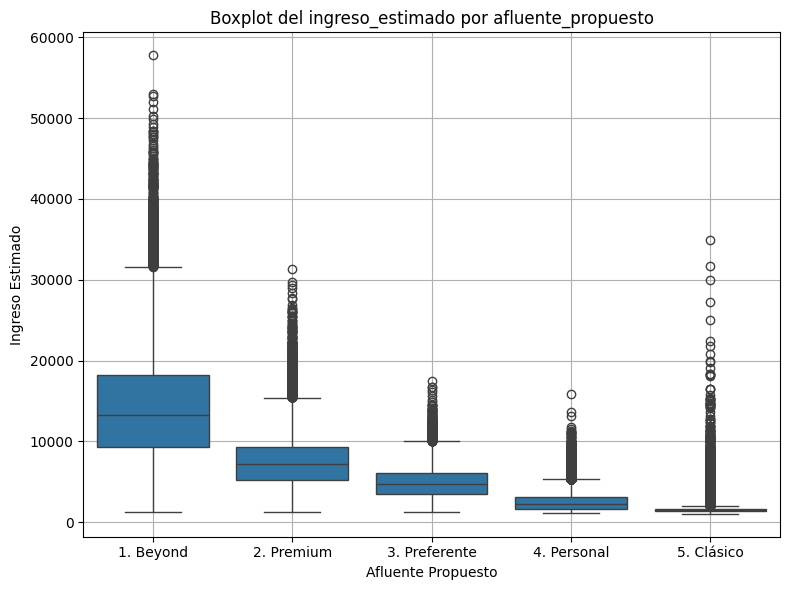

In [150]:
plt.figure(figsize=(8, 6))
sns.boxplot(x='AFLUENTE_PROPUESTO_2026', y='y_pred_oot3', data=df_oot3_segm, order=orden)
plt.title('Boxplot del ingreso_estimado por afluente_propuesto')
plt.xlabel('Afluente Propuesto')
plt.ylabel('Ingreso Estimado')
plt.grid(True)
plt.tight_layout()
plt.show()

---

##### 4.2.5.3. Métricas: Segmento Top

In [199]:
X_train = df_train.query("ingreso_malbie23.notnull() and SEGMENTO_V3=='01. Top'")[features_rfe_best]
X_test = df_test.query("ingreso_malbie23.notnull() and SEGMENTO_V3=='01. Top'")[features_rfe_best]
X_oot1 = df_oot1.query("ingreso_malbie23.notnull() and SEGMENTO_V3=='01. Top'")[features_rfe_best]

In [200]:
y_pred_train = np.exp(gbm.predict(X_train))
y_real_train = df_train.query("ingreso_malbie23.notnull() and SEGMENTO_V3=='01. Top'")["INGRESO_CAP_V2"]

y_pred_test = np.exp(gbm.predict(X_test))
y_real_test = df_test.query("ingreso_malbie23.notnull() and SEGMENTO_V3=='01. Top'")["INGRESO_CAP_V2"]

y_pred_oot1= np.exp(gbm.predict(X_oot1))
y_real_oot1 = df_oot1.query("ingreso_malbie23.notnull() and SEGMENTO_V3=='01. Top'")["INGRESO_CAP_V2"]

In [201]:
sbp.metricas_regresion_v2(y_real_train,y_pred_train,y_real_test,y_pred_test,y_real_oot1,y_pred_oot1,y_real_oot1,y_pred_oot1,y_real_oot1,y_pred_oot1)

,MAE,MAPE,MSE,RMSE,RMSPE,R2
Train,3672.487899,0.396405,3.377489e+07,5811.617181,0.678949,0.458966
Test,3832.668940,0.406795,3.701423e+07,6083.932481,0.680156,0.452252
OOT1,3785.885366,0.394156,3.553295e+07,5960.952021,0.668168,0.454072
OOT2,3785.885366,0.394156,3.553295e+07,5960.952021,0.668168,0.454072
OOT3,3785.885366,0.394156,3.553295e+07,5960.952021,0.668168,0.454072


In [206]:
sbp.calcular_coincidencia_v2(y_real_train,y_pred_train,y_real_test,y_pred_test,y_real_oot1,y_pred_oot1,y_real_oot1,y_pred_oot1,y_real_oot1,y_pred_oot1,0.20)

,Subestimacion,Coincidencia,Sobreestimacion
Train,0.262579,0.397768,0.339653
Test,0.267237,0.382871,0.349892
OOT1,0.276234,0.392682,0.331084
OOT2,0.276234,0.392682,0.331084
OOT3,0.276234,0.392682,0.331084


In [207]:
sbp.calcular_coincidencia_v2(y_real_train,y_pred_train,y_real_test,y_pred_test,y_real_oot1,y_pred_oot1,y_real_oot1,y_pred_oot1,y_real_oot1,y_pred_oot1,0.25)

,Subestimacion,Coincidencia,Sobreestimacion
Train,0.215935,0.479979,0.304087
Test,0.225120,0.462286,0.312593
OOT1,0.229548,0.475492,0.294960
OOT2,0.229548,0.475492,0.294960
OOT3,0.229548,0.475492,0.294960


In [208]:
sbp.calcular_coincidencia_v2(y_real_train,y_pred_train,y_real_test,y_pred_test,y_real_oot1,y_pred_oot1,y_real_oot1,y_pred_oot1,y_real_oot1,y_pred_oot1,0.30)

,Subestimacion,Coincidencia,Sobreestimacion
Train,0.175314,0.554618,0.270068
Test,0.184167,0.536219,0.279615
OOT1,0.185692,0.552520,0.261788
OOT2,0.185692,0.552520,0.261788
OOT3,0.185692,0.552520,0.261788


OOT1

In [68]:
bins = [999,1500,2000,3500,5000,7000,10000,12500,15000,float("inf")]
sbp.calcular_precision_x_intervalos(y_pred_oot1,y_real_oot1,0.25,bins)

,Casos,Casos (%),Prom. real,Prom. pred,Subestimacion,Coincidencia,Sobreestimacion
Intervalos,,,,,,,
"(999.0, 1500.0]",394,0.006816,1240.178693,5272.558774,0.000000,0.007614,0.992386
"(1500.0, 2000.0]",488,0.008442,1765.428358,5665.592896,0.002049,0.045082,0.952869
"(2000.0, 3500.0]",2640,0.045672,2870.049782,5985.387132,0.005303,0.105303,0.889394
"(3500.0, 5000.0]",5638,0.097537,4351.609009,6608.437389,0.018624,0.288578,0.692799
"(5000.0, 7000.0]",11136,0.192651,6026.458050,7520.659624,0.034124,0.560075,0.405801
"(7000.0, 10000.0]",13929,0.240969,8411.731744,8963.237635,0.138129,0.626894,0.234977
"(10000.0, 12500.0]",7176,0.124144,11200.216304,10679.813697,0.268952,0.578595,0.152453
"(12500.0, 15000.0]",4843,0.083783,13731.999260,12118.001644,0.388602,0.493083,0.118315
"(15000.0, inf]",11560,0.199986,24272.673219,16617.485435,0.591696,0.360813,0.047491


In [209]:
bins = [999,1500,2000,3500,5000,7000,10000,12500,15000,float("inf")]
sbp.calcular_precision_x_intervalos(y_pred_oot1,y_real_oot1,0.3,bins)

,Casos,Casos (%),Prom. real,Prom. pred,Subestimacion,Coincidencia,Sobreestimacion
Intervalos,,,,,,,
"(999.0, 1500.0]",394,0.006800,1240.358896,5253.383026,0.000000,0.010152,0.989848
"(1500.0, 2000.0]",492,0.008492,1765.901827,5643.144698,0.000000,0.056911,0.943089
"(2000.0, 3500.0]",2648,0.045702,2868.816800,5974.766086,0.003399,0.127266,0.869335
"(3500.0, 5000.0]",5655,0.097601,4351.708945,6599.069468,0.011317,0.355084,0.633599
"(5000.0, 7000.0]",11165,0.192699,6026.262811,7500.711506,0.022033,0.631706,0.346261
"(7000.0, 10000.0]",13966,0.241042,8411.371683,8932.686004,0.090577,0.715810,0.193613
"(10000.0, 12500.0]",7192,0.124128,11201.027312,10650.521079,0.207870,0.665462,0.126669
"(12500.0, 15000.0]",4847,0.083656,13731.943858,12104.500364,0.320198,0.576233,0.103569
"(15000.0, inf]",11581,0.199879,24271.755837,16557.769233,0.529143,0.432346,0.038511


Afluente 2025

In [ ]:
sbp.calcular_precision_x_categorias_segmento(y_pred_oot1,y_real_oot1,
                                        df_oot1.query("ingreso_malbie23.notnull() and SEGMENTO_V3=='01. Top'")['afluente_propuesto_mt'],0.25)

,Casos,Casos (%),Prom. real,Prom. pred.,Subestimacion,Coincidencia,Sobreestimacion
Categoría,,,,,,,
1. Beyond,10813,0.187063,22198.935922,17155.169571,0.458615,0.384907,0.156478
2. Premium,29777,0.515137,10124.055497,9902.594088,0.212950,0.504483,0.282567
3. Preferente,12393,0.214397,6311.659900,6946.970134,0.096667,0.517954,0.385379
4. Personal,4302,0.074424,4910.759133,5530.888928,0.106230,0.420967,0.472803
5. Clásico,519,0.008979,8401.649706,7069.115684,0.233141,0.377649,0.389210


In [ ]:
sbp.calcular_precision_x_categorias_segmento(y_pred_oot1,y_real_oot1,
                                        df_oot1.query("ingreso_malbie23.notnull() and SEGMENTO_V3=='01. Top'")['afluente_propuesto_mt'],0.3)

,Casos,Casos (%),Prom. real,Prom. pred.,Subestimacion,Coincidencia,Sobreestimacion
Categoría,,,,,,,
1. Beyond,10813,0.187063,22198.935922,17155.169571,0.400074,0.459909,0.140017
2. Premium,29777,0.515137,10124.055497,9902.594088,0.164758,0.583437,0.251805
3. Preferente,12393,0.214397,6311.659900,6946.970134,0.072783,0.588397,0.338820
4. Personal,4302,0.074424,4910.759133,5530.888928,0.077406,0.499768,0.422827
5. Clásico,519,0.008979,8401.649706,7069.115684,0.202312,0.435453,0.362235


---

Percentiles: OOT 1

In [73]:
df_oot1_segm = df_oot1.query("ingreso_malbie23.notnull() and SEGMENTO_V3=='01. Top'")
df_oot1_segm['y_pred_oot1'] = y_pred_oot1
df_oot1_segm = df_oot1_segm[['afluente_propuesto_mt','y_pred_oot1']]

orden= sorted(df_oot1_segm['afluente_propuesto_mt'].unique())

In [74]:
df_oot1_segm.groupby('afluente_propuesto_mt')['y_pred_oot1'].describe()

,count,mean,std,min,25%,50%,75%,max
afluente_propuesto_mt,,,,,,,,
1. Beyond,10813.0,17155.169571,7450.761753,2641.960842,11779.788594,15895.702760,21221.973290,52367.393613
2. Premium,29777.0,9902.594088,3476.959852,1496.140748,7513.577127,9293.936151,11627.292621,37617.008687
3. Preferente,12393.0,6946.970134,1760.008610,1776.014968,5771.283458,6680.698925,7833.320307,34341.700601
4. Personal,4302.0,5530.888928,1656.045512,1395.418120,4519.060343,5373.901473,6390.149400,17766.579303
5. Clásico,519.0,7069.115684,4816.300163,1373.815684,4170.946873,6097.826029,8309.109689,44755.173038


In [75]:
percentiles = [0.05, 0.10, 0.15,0.25,0.50,0.75, 0.85, 0.90, 0.95]
percentiles_group = df_oot1_segm.groupby('afluente_propuesto_mt')['y_pred_oot1'].quantile(percentiles).unstack()
percentiles_group.columns = ["perc_5", "perc_10", "perc_15","perc_25","perc_50","perc_75", "perc_85", "perc_90", "perc_95"]
percentiles_group

,perc_5,perc_10,perc_15,perc_25,perc_50,perc_75,perc_85,perc_90,perc_95
afluente_propuesto_mt,,,,,,,,,
1. Beyond,7320.877056,8864.014748,9937.167016,11779.788594,15895.702760,21221.973290,24580.773531,27349.852263,31459.167813
2. Premium,5500.260448,6220.683110,6736.724806,7513.577127,9293.936151,11627.292621,13218.663448,14436.091469,16429.091510
3. Preferente,4619.399702,5087.380820,5360.131797,5771.283458,6680.698925,7833.320307,8576.058374,9147.491324,10114.348945
4. Personal,3083.741743,3605.341163,3996.437011,4519.060343,5373.901473,6390.149400,7041.459701,7562.785132,8406.370011
5. Clásico,2033.988661,2684.236629,3015.721968,4170.946873,6097.826029,8309.109689,10331.970183,12071.165448,16248.742295


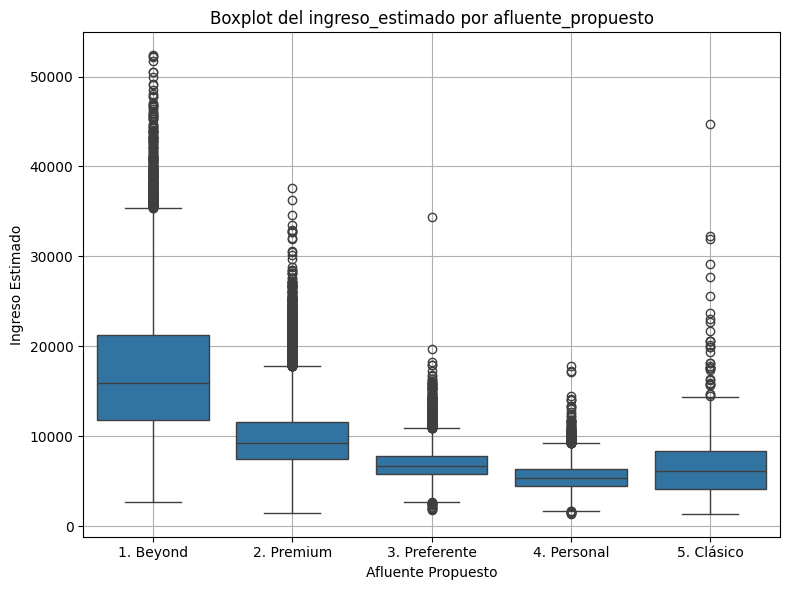

In [76]:
plt.figure(figsize=(8, 6))
sns.boxplot(x='afluente_propuesto_mt', y='y_pred_oot1', data=df_oot1_segm, order=orden)
plt.title('Boxplot del ingreso_estimado por afluente_propuesto')
plt.xlabel('Afluente Propuesto')
plt.ylabel('Ingreso Estimado')
plt.grid(True)
plt.tight_layout()
plt.show()

---

# 5.Benchmark

In [145]:
df_train1 = df_train.query("ingreso_malbie23.notna()")
df_test1 = df_test.query("ingreso_malbie23.notna()")

df_oot11 = df_oot1.query("ingreso_malbie23.notna()")
df_oot21 = df_oot2.query("INGRESO_MALBIE23.notna()")
df_oot31 = df_oot3.query("INGRESO_MALBIE23.notna()")

In [146]:
y_pred_train_b = df_train1["ingreso_malbie23"]
y_real_train_b = df_train1["INGRESO_CAP_V2"]
y_pred_test_b = df_test1["ingreso_malbie23"]
y_real_test_b = df_test1["INGRESO_CAP_V2"]

y_pred_oot1_b= df_oot11["ingreso_malbie23"]
y_real_oot1_b = df_oot11["INGRESO_CAP_V2"]
y_pred_oot2_b= df_oot21["INGRESO_MALBIE23"]
y_real_oot2_b = df_oot21["INGRESO_CAP_V2"]
y_pred_oot3_b= df_oot31["INGRESO_MALBIE23"]
y_real_oot3_b = df_oot31["INGRESO_CAP_V2"]

In [147]:
sbp.metricas_regresion_v2(y_real_train_b,y_pred_train_b,y_real_test_b,y_pred_test_b,y_real_oot1_b,y_pred_oot1_b,y_real_oot2_b,y_pred_oot2_b,y_real_oot3_b,y_pred_oot3_b)

,MAE,MAPE,MSE,RMSE,RMSPE,R2
Train,1339.132198,0.308563,8.488117e+06,2913.437263,0.427166,0.481490
Test,1356.787942,0.309234,8.878736e+06,2979.720847,0.428966,0.480659
OOT1,1425.870852,0.313974,9.292802e+06,3048.409788,0.428301,0.479146
OOT2,1347.916049,0.310760,8.129163e+06,2851.168733,0.424156,0.491840
OOT3,1382.955933,0.314565,8.449393e+06,2906.783943,0.424159,0.486646


---

In [148]:
sbp.calcular_coincidencia_v2(y_real_train_b,y_pred_train_b,y_real_test_b,y_pred_test_b,y_real_oot1_b,y_pred_oot1_b,y_real_oot2_b,y_pred_oot2_b,y_real_oot3_b,y_pred_oot3_b,0.20)

,Subestimacion,Coincidencia,Sobreestimacion
Train,0.407140,0.408069,0.184791
Test,0.409598,0.405628,0.184774
OOT1,0.432429,0.394029,0.173542
OOT2,0.431078,0.396370,0.172552
OOT3,0.447411,0.385251,0.167338


In [149]:
sbp.calcular_coincidencia_v2(y_real_train_b,y_pred_train_b,y_real_test_b,y_pred_test_b,y_real_oot1_b,y_pred_oot1_b,y_real_oot2_b,y_pred_oot2_b,y_real_oot3_b,y_pred_oot3_b,0.25)

,Subestimacion,Coincidencia,Sobreestimacion
Train,0.352014,0.494611,0.153375
Test,0.353437,0.492638,0.153924
OOT1,0.375741,0.480396,0.143862
OOT2,0.372959,0.484031,0.143010
OOT3,0.388413,0.473131,0.138456


In [150]:
sbp.calcular_coincidencia_v2(y_real_train_b,y_pred_train_b,y_real_test_b,y_pred_test_b,y_real_oot1_b,y_pred_oot1_b,y_real_oot2_b,y_pred_oot2_b,y_real_oot3_b,y_pred_oot3_b,0.30)

,Subestimacion,Coincidencia,Sobreestimacion
Train,0.299385,0.574880,0.125735
Test,0.300956,0.572306,0.126738
OOT1,0.321363,0.560461,0.118176
OOT2,0.317076,0.565438,0.117486
OOT3,0.330956,0.555619,0.113425


---

Rangos de ingreso

In [151]:
bins = [999,1500,2000,3500,5000,7000,10000,12500,15000,float("inf")]

train

In [152]:
display(sbp.calcular_precision_x_intervalos_v3(y_pred_train_b,y_real_train_b,0.25,bins))
display(sbp.calcular_precision_x_intervalos_v3(y_pred_train_b,y_real_train_b,0.30,bins))

,Casos,Casos (%),Prom. real,Prom. pred,MAE,MAPE,RMSPE,Subestimacion,Coincidencia,Sobreestimacion
Intervalos,,,,,,,,,,
"(999.0, 1500.0]",113872,0.223630,1252.576898,1579.112385,349.191152,0.292992,0.500709,0.000009,0.589214,0.410777
"(1500.0, 2000.0]",96720,0.189946,1733.457359,1689.816047,340.168618,0.194120,0.325350,0.098935,0.802161,0.098904
"(2000.0, 3500.0]",152741,0.299964,2662.423505,2193.007048,807.191955,0.299455,0.378638,0.505228,0.417412,0.077360
"(3500.0, 5000.0]",57026,0.111992,4167.148132,3049.840077,1653.188239,0.395881,0.458627,0.610616,0.299635,0.089749
"(5000.0, 7000.0]",37403,0.073455,5881.148866,4238.251034,2305.846240,0.392462,0.459785,0.585595,0.330642,0.083763
"(7000.0, 10000.0]",25122,0.049336,8308.575717,5639.696756,3233.427474,0.388545,0.456536,0.607197,0.341135,0.051668
"(10000.0, 12500.0]",9625,0.018902,11160.815629,7008.941913,4581.947291,0.410030,0.472212,0.685403,0.286649,0.027948
"(12500.0, 15000.0]",5684,0.011163,13686.744728,8140.829511,5865.651195,0.428124,0.484951,0.739092,0.245074,0.015834
"(15000.0, inf]",11005,0.021612,23821.162603,10568.795538,13333.564603,0.531195,0.572571,0.884144,0.112949,0.002908


,Casos,Casos (%),Prom. real,Prom. pred,MAE,MAPE,RMSPE,Subestimacion,Coincidencia,Sobreestimacion
Intervalos,,,,,,,,,,
"(999.0, 1500.0]",113872,0.223630,1252.576898,1579.112385,349.191152,0.292992,0.500709,0.000000,0.670165,0.329835
"(1500.0, 2000.0]",96720,0.189946,1733.457359,1689.816047,340.168618,0.194120,0.325350,0.028763,0.887645,0.083592
"(2000.0, 3500.0]",152741,0.299964,2662.423505,2193.007048,807.191955,0.299455,0.378638,0.421013,0.512790,0.066197
"(3500.0, 5000.0]",57026,0.111992,4167.148132,3049.840077,1653.188239,0.395881,0.458627,0.566987,0.356101,0.076912
"(5000.0, 7000.0]",37403,0.073455,5881.148866,4238.251034,2305.846240,0.392462,0.459785,0.536508,0.394140,0.069353
"(7000.0, 10000.0]",25122,0.049336,8308.575717,5639.696756,3233.427474,0.388545,0.456536,0.551548,0.408288,0.040164
"(10000.0, 12500.0]",9625,0.018902,11160.815629,7008.941913,4581.947291,0.410030,0.472212,0.622338,0.356675,0.020987
"(12500.0, 15000.0]",5684,0.011163,13686.744728,8140.829511,5865.651195,0.428124,0.484951,0.674525,0.315095,0.010380
"(15000.0, inf]",11005,0.021612,23821.162603,10568.795538,13333.564603,0.531195,0.572571,0.843071,0.155202,0.001726


oot1

In [153]:
display(sbp.calcular_precision_x_intervalos_v3(y_pred_oot1_b,y_real_oot1_b,0.25,bins))
display(sbp.calcular_precision_x_intervalos_v3(y_pred_oot1_b,y_real_oot1_b,0.30,bins))

,Casos,Casos (%),Prom. real,Prom. pred,MAE,MAPE,RMSPE,Subestimacion,Coincidencia,Sobreestimacion
Intervalos,,,,,,,,,,
"(999.0, 1500.0]",117047,0.203238,1255.798294,1584.152567,351.216507,0.293447,0.502753,0.000000,0.592078,0.407922
"(1500.0, 2000.0]",109309,0.189802,1735.764121,1689.208928,341.164960,0.194502,0.324861,0.100879,0.800785,0.098336
"(2000.0, 3500.0]",174349,0.302735,2660.231905,2162.453440,822.064679,0.304795,0.381389,0.524368,0.401195,0.074437
"(3500.0, 5000.0]",66737,0.115881,4170.806318,2999.812219,1682.882703,0.402766,0.462508,0.632003,0.282797,0.085200
"(5000.0, 7000.0]",45341,0.078729,5880.112276,4178.526292,2333.659646,0.397052,0.462094,0.599832,0.319159,0.081008
"(7000.0, 10000.0]",30518,0.052991,8311.004751,5604.547388,3259.463084,0.391411,0.457686,0.617111,0.331673,0.051216
"(10000.0, 12500.0]",11696,0.020309,11166.152275,6994.159749,4571.453864,0.408930,0.469440,0.689979,0.284371,0.025650
"(12500.0, 15000.0]",6902,0.011984,13700.161520,8079.636279,5931.468350,0.432541,0.487261,0.748768,0.233411,0.017821
"(15000.0, inf]",14013,0.024332,23885.792374,10585.996432,13376.773134,0.533607,0.572855,0.891886,0.105688,0.002426


,Casos,Casos (%),Prom. real,Prom. pred,MAE,MAPE,RMSPE,Subestimacion,Coincidencia,Sobreestimacion
Intervalos,,,,,,,,,,
"(999.0, 1500.0]",117047,0.203238,1255.798294,1584.152567,351.216507,0.293447,0.502753,0.000000,0.672123,0.327877
"(1500.0, 2000.0]",109309,0.189802,1735.764121,1689.208928,341.164960,0.194502,0.324861,0.029705,0.887054,0.083241
"(2000.0, 3500.0]",174349,0.302735,2660.231905,2162.453440,822.064679,0.304795,0.381389,0.437794,0.498368,0.063837
"(3500.0, 5000.0]",66737,0.115881,4170.806318,2999.812219,1682.882703,0.402766,0.462508,0.589508,0.337579,0.072913
"(5000.0, 7000.0]",45341,0.078729,5880.112276,4178.526292,2333.659646,0.397052,0.462094,0.552612,0.381619,0.065768
"(7000.0, 10000.0]",30518,0.052991,8311.004751,5604.547388,3259.463084,0.391411,0.457686,0.560161,0.398748,0.041091
"(10000.0, 12500.0]",11696,0.020309,11166.152275,6994.159749,4571.453864,0.408930,0.469440,0.624145,0.355592,0.020263
"(12500.0, 15000.0]",6902,0.011984,13700.161520,8079.636279,5931.468350,0.432541,0.487261,0.684294,0.302666,0.013040
"(15000.0, inf]",14013,0.024332,23885.792374,10585.996432,13376.773134,0.533607,0.572855,0.855277,0.143010,0.001713


oot2

In [154]:
display(sbp.calcular_precision_x_intervalos_v3(y_pred_oot2_b,y_real_oot2_b,0.25,bins))
display(sbp.calcular_precision_x_intervalos_v3(y_pred_oot2_b,y_real_oot2_b,0.3,bins))

,Casos,Casos (%),Prom. real,Prom. pred,MAE,MAPE,RMSPE,Subestimacion,Coincidencia,Sobreestimacion
Intervalos,,,,,,,,,,
"(999.0, 1500.0]",121612,0.204411,1254.410267,1582.250899,349.705943,0.292830,0.501228,0.000000,0.591463,0.408537
"(1500.0, 2000.0]",117157,0.196923,1738.788340,1681.967883,338.237229,0.192479,0.319259,0.102367,0.803418,0.094215
"(2000.0, 3500.0]",180955,0.304157,2657.868747,2143.236059,827.846423,0.307049,0.380245,0.535619,0.391921,0.072460
"(3500.0, 5000.0]",68874,0.115766,4165.889135,2991.474880,1679.587645,0.402654,0.462794,0.634013,0.281500,0.084488
"(5000.0, 7000.0]",45604,0.076653,5882.542216,4190.253449,2300.437057,0.391404,0.456437,0.595408,0.327120,0.077471
"(7000.0, 10000.0]",30552,0.051353,8298.816525,5612.714426,3214.834822,0.386826,0.453840,0.613348,0.338701,0.047951
"(10000.0, 12500.0]",11247,0.018904,11154.722069,7097.031142,4454.610398,0.398957,0.459973,0.676269,0.298569,0.025162
"(12500.0, 15000.0]",6402,0.010761,13685.429364,8202.222307,5821.142043,0.424869,0.480341,0.741331,0.240394,0.018276
"(15000.0, inf]",12536,0.021071,23769.417205,10795.956675,13065.805650,0.522661,0.563135,0.882339,0.115108,0.002553


,Casos,Casos (%),Prom. real,Prom. pred,MAE,MAPE,RMSPE,Subestimacion,Coincidencia,Sobreestimacion
Intervalos,,,,,,,,,,
"(999.0, 1500.0]",121612,0.204411,1254.410267,1582.250899,349.705943,0.292830,0.501228,0.000000,0.671356,0.328644
"(1500.0, 2000.0]",117157,0.196923,1738.788340,1681.967883,338.237229,0.192479,0.319259,0.029516,0.891556,0.078928
"(2000.0, 3500.0]",180955,0.304157,2657.868747,2143.236059,827.846423,0.307049,0.380245,0.448001,0.489575,0.062424
"(3500.0, 5000.0]",68874,0.115766,4165.889135,2991.474880,1679.587645,0.402654,0.462794,0.589221,0.338139,0.072640
"(5000.0, 7000.0]",45604,0.076653,5882.542216,4190.253449,2300.437057,0.391404,0.456437,0.544843,0.391281,0.063876
"(7000.0, 10000.0]",30552,0.051353,8298.816525,5612.714426,3214.834822,0.386826,0.453840,0.555806,0.406684,0.037510
"(10000.0, 12500.0]",11247,0.018904,11154.722069,7097.031142,4454.610398,0.398957,0.459973,0.607540,0.373344,0.019116
"(12500.0, 15000.0]",6402,0.010761,13685.429364,8202.222307,5821.142043,0.424869,0.480341,0.675102,0.311934,0.012965
"(15000.0, inf]",12536,0.021071,23769.417205,10795.956675,13065.805650,0.522661,0.563135,0.841576,0.156270,0.002154


oot3

In [155]:
display(sbp.calcular_precision_x_intervalos_v3(y_pred_oot3_b,y_real_oot3_b,0.25,bins))
display(sbp.calcular_precision_x_intervalos_v3(y_pred_oot3_b,y_real_oot3_b,0.3,bins))

,Casos,Casos (%),Prom. real,Prom. pred,MAE,MAPE,RMSPE,Subestimacion,Coincidencia,Sobreestimacion
Intervalos,,,,,,,,,,
"(999.0, 1500.0]",118856,0.198613,1251.533220,1578.756372,349.371848,0.293483,0.500310,0.000000,0.590681,0.409319
"(1500.0, 2000.0]",115181,0.192472,1742.797155,1674.234917,342.370814,0.194258,0.314941,0.112371,0.795669,0.091960
"(2000.0, 3500.0]",184311,0.307991,2657.136709,2115.745056,835.537156,0.309881,0.379488,0.551340,0.380428,0.068232
"(3500.0, 5000.0]",71047,0.118722,4164.756758,2937.661422,1699.612746,0.407548,0.465497,0.649415,0.271074,0.079511
"(5000.0, 7000.0]",46559,0.077802,5884.413608,4146.208619,2324.929059,0.395473,0.460286,0.603299,0.322022,0.074679
"(7000.0, 10000.0]",31509,0.052653,8293.992197,5578.967568,3230.262341,0.388951,0.455429,0.617474,0.336221,0.046304
"(10000.0, 12500.0]",11329,0.018931,11140.905147,7073.994330,4472.080771,0.400921,0.461878,0.679142,0.293318,0.027540
"(12500.0, 15000.0]",6499,0.010860,13702.086152,8109.172045,5914.830570,0.430993,0.486404,0.743807,0.239421,0.016772
"(15000.0, inf]",13139,0.021956,23813.497443,10744.014589,13148.511722,0.525690,0.565186,0.887815,0.109750,0.002435


,Casos,Casos (%),Prom. real,Prom. pred,MAE,MAPE,RMSPE,Subestimacion,Coincidencia,Sobreestimacion
Intervalos,,,,,,,,,,
"(999.0, 1500.0]",118856,0.198613,1251.533220,1578.756372,349.371848,0.293483,0.500310,0.000000,0.671207,0.328793
"(1500.0, 2000.0]",115181,0.192472,1742.797155,1674.234917,342.370814,0.194258,0.314941,0.032853,0.889930,0.077218
"(2000.0, 3500.0]",184311,0.307991,2657.136709,2115.745056,835.537156,0.309881,0.379488,0.463054,0.478566,0.058380
"(3500.0, 5000.0]",71047,0.118722,4164.756758,2937.661422,1699.612746,0.407548,0.465497,0.605050,0.326629,0.068321
"(5000.0, 7000.0]",46559,0.077802,5884.413608,4146.208619,2324.929059,0.395473,0.460286,0.553942,0.385618,0.060439
"(7000.0, 10000.0]",31509,0.052653,8293.992197,5578.967568,3230.262341,0.388951,0.455429,0.558920,0.404488,0.036593
"(10000.0, 12500.0]",11329,0.018931,11140.905147,7073.994330,4472.080771,0.400921,0.461878,0.612940,0.367376,0.019684
"(12500.0, 15000.0]",6499,0.010860,13702.086152,8109.172045,5914.830570,0.430993,0.486404,0.683644,0.304201,0.012156
"(15000.0, inf]",13139,0.021956,23813.497443,10744.014589,13148.511722,0.525690,0.565186,0.848466,0.149935,0.001598


---

Afluente 2025

oot1

In [ ]:
sbp.calcular_precision_x_categorias_segmento(y_pred_oot1_b,y_real_oot1_b,
                                        df_oot11['afluente_propuesto_mt'],0.3)

,Casos,Casos (%),Prom. real,Prom. pred.,Subestimacion,Coincidencia,Sobreestimacion
Categoría,,,,,,,
1. Beyond,12266,0.021510,21754.484711,11232.042716,0.714006,0.233654,0.052340
2. Premium,49014,0.085952,9666.430903,6697.647487,0.490921,0.392929,0.116150
3. Preferente,46317,0.081223,5879.764374,4362.128716,0.458233,0.399098,0.142669
4. Personal,225922,0.396183,3155.220339,2371.535794,0.434911,0.469941,0.095148
5. Clásico,236727,0.415131,1770.988540,1576.760181,0.137403,0.723686,0.138911


oot2

In [ ]:
sbp.calcular_precision_x_categorias_segmento(y_pred_oot2_b,y_real_oot2_b,
                                        df_oot21['Afluente_Propuesto_MT'],0.3)

,Casos,Casos (%),Prom. real,Prom. pred.,Subestimacion,Coincidencia,Sobreestimacion
Categoría,,,,,,,
1. Beyond,11881,0.019970,21286.967362,11153.775304,0.699436,0.246276,0.054288
2. Premium,48395,0.081344,9311.609567,6629.394753,0.476103,0.410373,0.113524
3. Preferente,46827,0.078709,5776.836298,4353.552581,0.448053,0.413031,0.138916
4. Personal,231655,0.389376,3122.459375,2373.403363,0.429825,0.473359,0.096816
5. Clásico,256181,0.430600,1794.064352,1586.995218,0.143406,0.720655,0.135939


oot3

In [ ]:
sbp.calcular_precision_x_categorias_segmento(y_pred_oot3_b,y_real_oot3_b,
                                        df_oot31['Afluente_Propuesto_MT'],0.3)

,Casos,Casos (%),Prom. real,Prom. pred.,Subestimacion,Coincidencia,Sobreestimacion
Categoría,,,,,,,
1. Beyond,11710,0.019568,21537.968817,11251.487819,0.703672,0.243553,0.052775
2. Premium,47986,0.080186,9473.466071,6661.153255,0.481307,0.408348,0.110345
3. Preferente,46739,0.078103,5876.190551,4382.197407,0.451272,0.415328,0.133400
4. Personal,228950,0.382584,3188.259514,2387.835481,0.443123,0.462219,0.094658
5. Clásico,263045,0.439559,1852.071827,1593.186610,0.167929,0.702598,0.129472


---

Afluente 2026

oot1

In [ ]:
display(sbp.calcular_precision_x_categorias_segmento(y_pred_oot1_b,y_real_oot1_b, df_oot11['AFLUENTE_PROPUESTO_2026'],0.25))
display(sbp.calcular_precision_x_categorias_segmento(y_pred_oot1_b,y_real_oot1_b, df_oot11['AFLUENTE_PROPUESTO_2026'],0.30))

,Casos,Casos (%),Prom. real,Prom. pred.,Subestimacion,Coincidencia,Sobreestimacion
Categoría,,,,,,,
1. Beyond,16774,0.029415,20114.665355,10615.287850,0.742518,0.195839,0.061643
2. Premium,50581,0.088700,9037.998378,6231.962828,0.561436,0.315415,0.123149
3. Preferente,49353,0.086547,5593.092258,4110.418962,0.530809,0.323911,0.145280
4. Personal,237287,0.416113,3003.694098,2277.020342,0.504339,0.396157,0.099504
5. Clásico,216251,0.379224,1672.642704,1575.422448,0.134903,0.662439,0.202658


,Casos,Casos (%),Prom. real,Prom. pred.,Subestimacion,Coincidencia,Sobreestimacion
Categoría,,,,,,,
1. Beyond,16774,0.029415,20114.665355,10615.287850,0.695898,0.249314,0.054787
2. Premium,50581,0.088700,9037.998378,6231.962828,0.506712,0.384729,0.108559
3. Preferente,49353,0.086547,5593.092258,4110.418962,0.484489,0.387028,0.128483
4. Personal,237287,0.416113,3003.694098,2277.020342,0.433838,0.479554,0.086608
5. Clásico,216251,0.379224,1672.642704,1575.422448,0.095579,0.747099,0.157322


oot2

In [ ]:
display(sbp.calcular_precision_x_categorias_segmento(y_pred_oot2_b,y_real_oot2_b,df_oot21['AFLUENTE_PROPUESTO_2026'],0.25))
display(sbp.calcular_precision_x_categorias_segmento(y_pred_oot2_b,y_real_oot2_b,df_oot21['AFLUENTE_PROPUESTO_2026'],0.30))

,Casos,Casos (%),Prom. real,Prom. pred.,Subestimacion,Coincidencia,Sobreestimacion
Categoría,,,,,,,
1. Beyond,17262,0.029015,19897.924785,10498.074706,0.748175,0.191287,0.060538
2. Premium,51880,0.087202,8609.322553,6128.343820,0.555378,0.320123,0.124499
3. Preferente,50834,0.085444,5396.589140,4032.199296,0.529429,0.323189,0.147382
4. Personal,253144,0.425496,2915.919873,2225.682630,0.518567,0.386274,0.095159
5. Clásico,221819,0.372843,1597.648441,1559.978552,0.099067,0.693570,0.207363


,Casos,Casos (%),Prom. real,Prom. pred.,Subestimacion,Coincidencia,Sobreestimacion
Categoría,,,,,,,
1. Beyond,17262,0.029015,19897.924785,10498.074706,0.702062,0.243425,0.054513
2. Premium,51880,0.087202,8609.322553,6128.343820,0.500019,0.389206,0.110775
3. Preferente,50834,0.085444,5396.589140,4032.199296,0.482807,0.386513,0.130680
4. Personal,253144,0.425496,2915.919873,2225.682630,0.443384,0.473197,0.083419
5. Clásico,221819,0.372843,1597.648441,1559.978552,0.062204,0.777986,0.159810


oot3

In [ ]:
display(sbp.calcular_precision_x_categorias_segmento(y_pred_oot3_b,y_real_oot3_b,df_oot31['AFLUENTE_PROPUESTO_2026'],0.25))
display(sbp.calcular_precision_x_categorias_segmento(y_pred_oot3_b,y_real_oot3_b,df_oot31['AFLUENTE_PROPUESTO_2026'],0.30))

,Casos,Casos (%),Prom. real,Prom. pred.,Subestimacion,Coincidencia,Sobreestimacion
Categoría,,,,,,,
1. Beyond,17606,0.029420,20388.842577,10515.398188,0.767352,0.172896,0.059752
2. Premium,52601,0.087898,8692.030058,6132.926096,0.563069,0.314158,0.122773
3. Preferente,51398,0.085888,5450.403389,4015.085151,0.540274,0.316082,0.143644
4. Personal,257617,0.430488,2943.001236,2206.100515,0.550150,0.360819,0.089031
5. Clásico,219208,0.366305,1569.734951,1549.043662,0.090384,0.704208,0.205408


,Casos,Casos (%),Prom. real,Prom. pred.,Subestimacion,Coincidencia,Sobreestimacion
Categoría,,,,,,,
1. Beyond,17606,0.029420,20388.842577,10515.398188,0.724867,0.222765,0.052369
2. Premium,52601,0.087898,8692.030058,6132.926096,0.508260,0.382749,0.108990
3. Preferente,51398,0.085888,5450.403389,4015.085151,0.495661,0.376843,0.127495
4. Personal,257617,0.430488,2943.001236,2206.100515,0.475388,0.446605,0.078007
5. Clásico,219208,0.366305,1569.734951,1549.043662,0.048415,0.793867,0.157718


---

Percentiles:

oot1

In [ ]:
df_oot11_segm = df_oot11.query("ingreso_malbie23.notnull()")
df_oot11_segm['y_pred_oot1_b'] = y_pred_oot1_b
df_oot11_segm = df_oot11_segm[['afluente_propuesto_mt','y_pred_oot1_b']]

orden= sorted(df_oot11_segm['afluente_propuesto_mt'].unique())

In [ ]:
df_oot11_segm.groupby('afluente_propuesto_mt')['y_pred_oot1_b'].describe()

,count,mean,std,min,25%,50%,75%,max
afluente_propuesto_mt,,,,,,,,
1. Beyond,12312.0,11087.994931,4879.538429,1274.51,7606.085,10763.760,14330.0825,32656.30
2. Premium,49253.0,6637.466344,2947.377329,1233.70,4397.320,6591.620,8527.7800,21377.37
3. Preferente,46507.0,4316.240305,1840.062242,1128.96,2764.870,4272.410,5653.2850,18533.96
4. Personal,227952.0,2348.183651,949.772676,1091.69,1624.680,2053.445,2845.5250,14233.43
5. Clásico,234044.0,1564.760289,398.647202,1031.64,1373.390,1473.580,1648.2825,23614.89


In [ ]:
percentiles = [0.05, 0.10, 0.15,0.25,0.50,0.75, 0.85, 0.90, 0.95]
percentiles_group = df_oot11_segm.groupby('afluente_propuesto_mt')['y_pred_oot1_b'].quantile(percentiles).unstack()
percentiles_group.columns = ["perc_5", "perc_10", "perc_15","perc_25","perc_50","perc_75", "perc_85", "perc_90", "perc_95"]
percentiles_group

,perc_5,perc_10,perc_15,perc_25,perc_50,perc_75,perc_85,perc_90,perc_95
afluente_propuesto_mt,,,,,,,,,
1. Beyond,3351.9245,4833.773,5945.7095,7606.085,10763.760,14330.0825,16308.312,17573.546,19537.1540
2. Premium,2032.3400,2690.114,3339.3140,4397.320,6591.620,8527.7800,9647.782,10454.298,11761.2760
3. Preferente,1647.0600,1891.832,2148.5460,2764.870,4272.410,5653.2850,6303.205,6734.468,7346.5110
4. Personal,1372.9810,1433.432,1497.3300,1624.680,2053.445,2845.5250,3259.597,3653.050,4251.2425
5. Clásico,1284.7815,1313.910,1334.9200,1373.390,1473.580,1648.2825,1775.510,1882.057,2097.4900


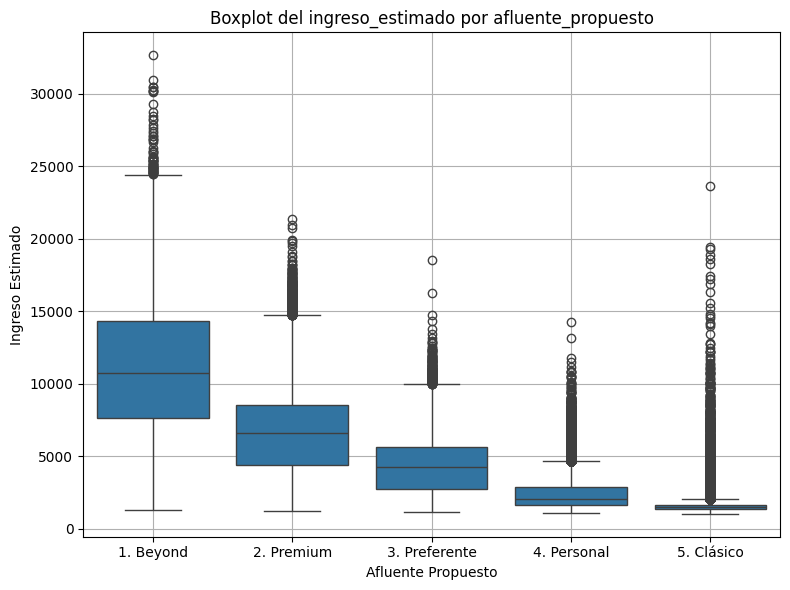

In [ ]:
plt.figure(figsize=(8, 6))
sns.boxplot(x='afluente_propuesto_mt', y='y_pred_oot1_b', data=df_oot11_segm, order=orden)
plt.title('Boxplot del ingreso_estimado por afluente_propuesto')
plt.xlabel('Afluente Propuesto')
plt.ylabel('Ingreso Estimado')
plt.grid(True)
plt.tight_layout()
plt.show()

oot2

In [69]:
df_oot21_segm = df_oot21.query("INGRESO_MALBIE23.notnull()")
df_oot21_segm['y_pred_oot2_b'] = y_pred_oot2_b
df_oot21_segm = df_oot21_segm[['AFLUENTE_PROPUESTO_2026','y_pred_oot2_b']]

orden= sorted(df_oot21_segm['AFLUENTE_PROPUESTO_2026'].unique())

In [74]:
df_oot21_segm.groupby('AFLUENTE_PROPUESTO_2026')['y_pred_oot2_b'].describe()

,count,mean,std,min,25%,50%,75%,max
AFLUENTE_PROPUESTO_2026,,,,,,,,
1. Beyond,17770.0,10417.915099,4667.268866,1247.84,7151.4500,9960.995,13386.9275,32252.44
2. Premium,52014.0,6097.935960,2713.057641,1229.59,3964.8775,6017.030,7977.5425,18193.69
3. Preferente,50873.0,4020.348667,1716.125200,1144.02,2501.3000,3905.700,5369.6700,11687.19
4. Personal,253771.0,2220.616556,854.310691,1042.01,1578.7200,1921.150,2691.0250,10002.53
5. Clásico,220511.0,1556.477790,371.564722,1024.14,1374.5800,1475.080,1646.0300,22522.03


In [75]:
percentiles = [0.05, 0.10, 0.15,0.25,0.50,0.75, 0.85, 0.90, 0.95]
percentiles_group = df_oot21_segm.groupby('AFLUENTE_PROPUESTO_2026')['y_pred_oot2_b'].quantile(percentiles).unstack()
percentiles_group.columns = ["perc_5", "perc_10", "perc_15","perc_25","perc_50","perc_75", "perc_85", "perc_90", "perc_95"]
percentiles_group

,perc_5,perc_10,perc_15,perc_25,perc_50,perc_75,perc_85,perc_90,perc_95
AFLUENTE_PROPUESTO_2026,,,,,,,,,
1. Beyond,3260.003,4595.209,5588.9925,7151.4500,9960.995,13386.9275,15297.6465,16660.794,18733.8985
2. Premium,1930.580,2448.377,2998.6650,3964.8775,6017.030,7977.5425,8951.0410,9657.992,10797.9240
3. Preferente,1607.222,1809.532,2006.0900,2501.3000,3905.700,5369.6700,5993.7820,6376.416,6912.6620
4. Personal,1358.850,1412.450,1467.7300,1578.7200,1921.150,2691.0250,3070.4950,3418.280,4005.9800
5. Clásico,1288.540,1318.180,1337.7800,1374.5800,1475.080,1646.0300,1765.3400,1860.910,2049.6350


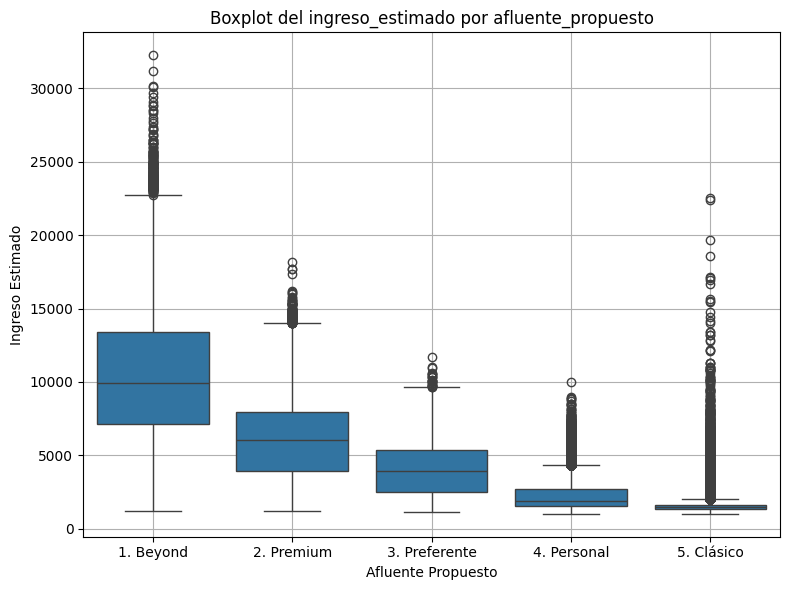

In [76]:
plt.figure(figsize=(8, 6))
sns.boxplot(x='AFLUENTE_PROPUESTO_2026', y='y_pred_oot2_b', data=df_oot21_segm, order=orden)
plt.title('Boxplot del ingreso_estimado por afluente_propuesto')
plt.xlabel('Afluente Propuesto')
plt.ylabel('Ingreso Estimado')
plt.grid(True)
plt.tight_layout()
plt.show()

oot3

In [71]:
df_oot31_segm = df_oot31.query("INGRESO_MALBIE23.notnull()")
df_oot31_segm['y_pred_oot3_b'] = y_pred_oot3_b
df_oot31_segm = df_oot31_segm[['AFLUENTE_PROPUESTO_2026','y_pred_oot3_b']]

orden= sorted(df_oot31_segm['AFLUENTE_PROPUESTO_2026'].unique())

In [72]:
df_oot31_segm.groupby('AFLUENTE_PROPUESTO_2026')['y_pred_oot3_b'].describe()

,count,mean,std,min,25%,50%,75%,max
AFLUENTE_PROPUESTO_2026,,,,,,,,
1. Beyond,17606.0,10515.398188,4680.108814,1204.42,7213.7975,10065.020,13576.2575,33297.58
2. Premium,52601.0,6132.926096,2708.902907,1194.19,4005.6100,6067.720,8013.8600,18420.09
3. Preferente,51398.0,4015.085151,1694.228507,1176.54,2514.5950,3915.115,5385.7250,12444.54
4. Personal,257617.0,2206.100515,838.909529,1071.66,1572.8800,1911.130,2669.8900,10719.34
5. Clásico,219208.0,1549.043662,364.210647,1012.53,1372.0475,1469.465,1637.4225,23776.07


In [73]:
percentiles = [0.05, 0.10, 0.15,0.25,0.50,0.75, 0.85, 0.90, 0.95]
percentiles_group = df_oot31_segm.groupby('AFLUENTE_PROPUESTO_2026')['y_pred_oot3_b'].quantile(percentiles).unstack()
percentiles_group.columns = ["perc_5", "perc_10", "perc_15","perc_25","perc_50","perc_75", "perc_85", "perc_90", "perc_95"]
percentiles_group

,perc_5,perc_10,perc_15,perc_25,perc_50,perc_75,perc_85,perc_90,perc_95
AFLUENTE_PROPUESTO_2026,,,,,,,,,
1. Beyond,3312.7225,4637.865,5684.4100,7213.7975,10065.020,13576.2575,15407.6925,16679.215,18748.2200
2. Premium,1934.9100,2452.830,3030.7900,4005.6100,6067.720,8013.8600,8979.8800,9686.010,10803.0700
3. Preferente,1601.3025,1805.922,2007.4915,2514.5950,3915.115,5385.7250,5968.4200,6347.536,6852.6365
4. Personal,1356.1880,1409.190,1462.2500,1572.8800,1911.130,2669.8900,3058.2700,3396.738,3972.2480
5. Clásico,1286.8500,1316.247,1336.0100,1372.0475,1469.465,1637.4225,1755.0500,1848.750,2030.3265


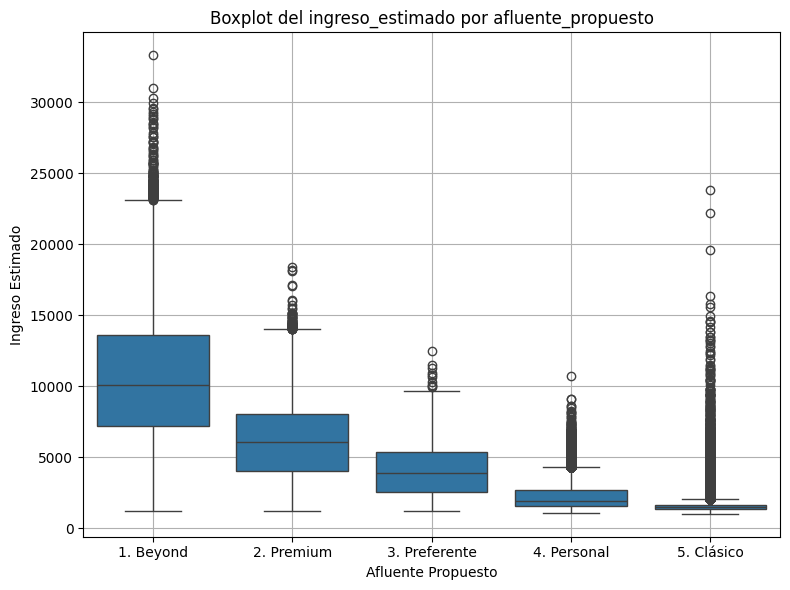

In [74]:
plt.figure(figsize=(8, 6))
sns.boxplot(x='AFLUENTE_PROPUESTO_2026', y='y_pred_oot3_b', data=df_oot31_segm, order=orden)
plt.title('Boxplot del ingreso_estimado por afluente_propuesto')
plt.xlabel('Afluente Propuesto')
plt.ylabel('Ingreso Estimado')
plt.grid(True)
plt.tight_layout()
plt.show()

---

# 6.PSI

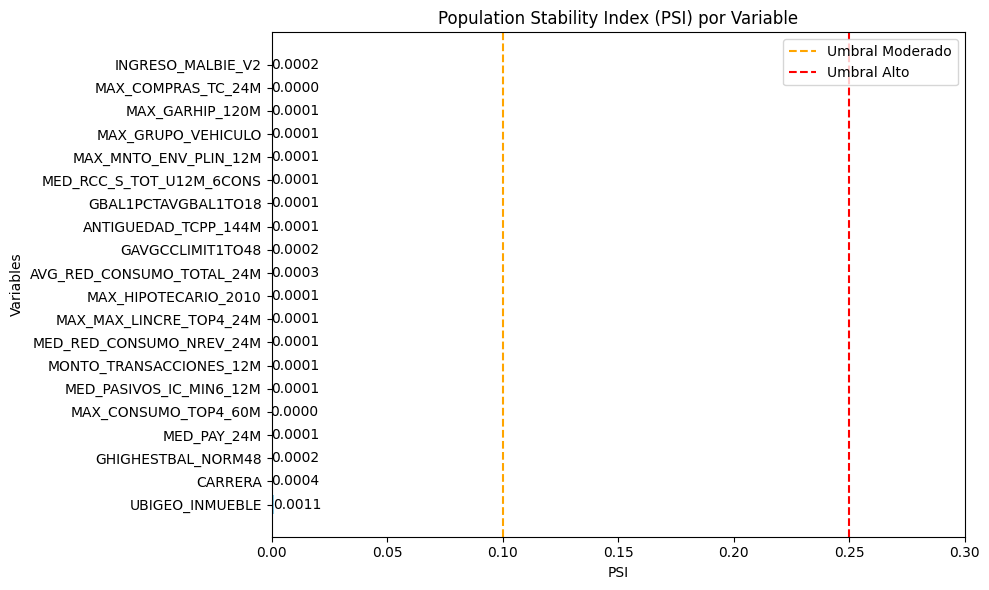

In [165]:
sbp.graficar_psi_variables(df_train, df_test,features_rfe_best+["INGRESO_MALBIE_V2"])

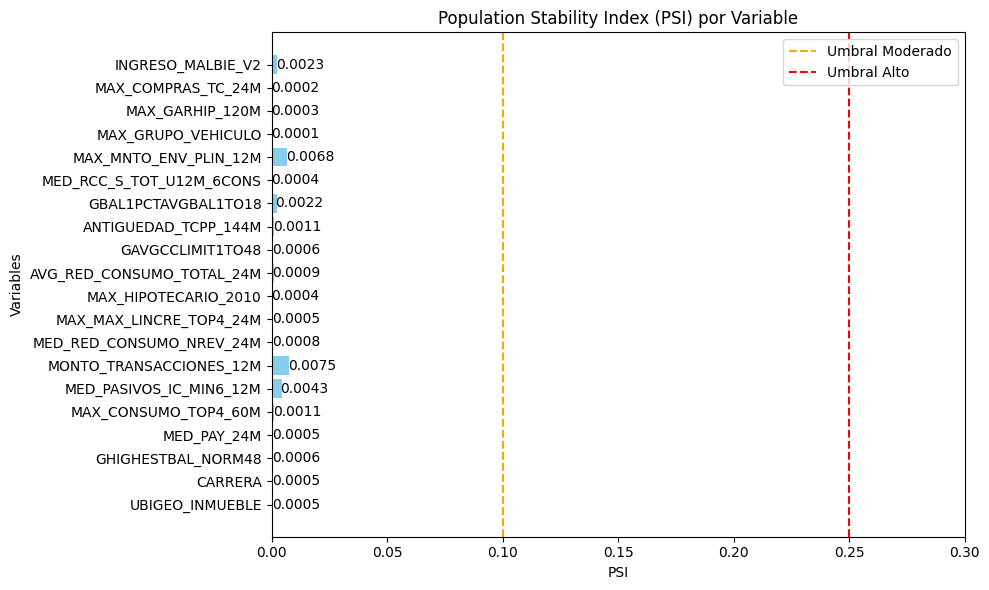

In [166]:
sbp.graficar_psi_variables(df_train, df_oot1,features_rfe_best+["INGRESO_MALBIE_V2"])

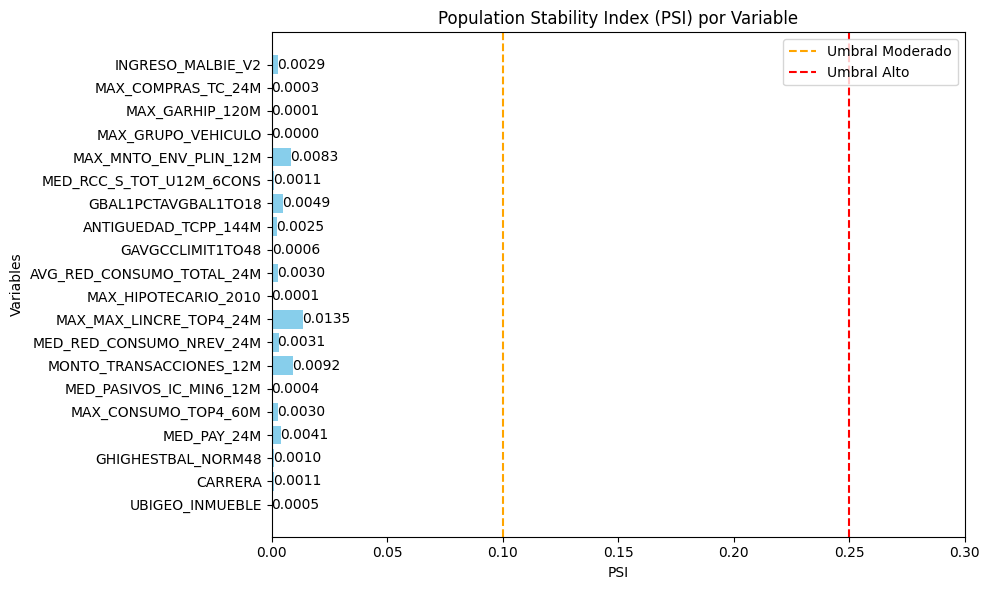

In [167]:
sbp.graficar_psi_variables(df_train, df_oot2,features_rfe_best+["INGRESO_MALBIE_V2"])

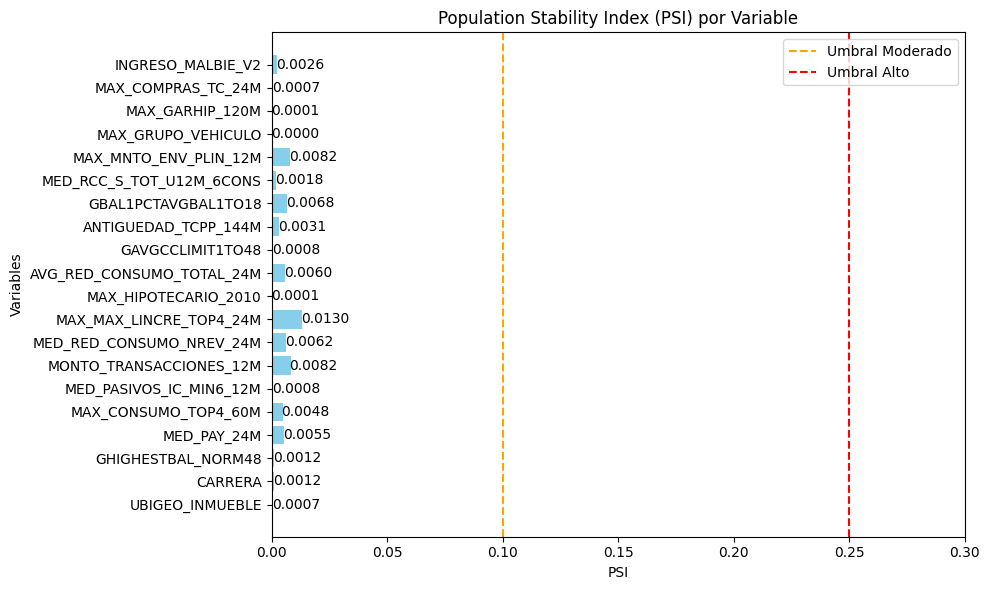

In [168]:
sbp.graficar_psi_variables(df_train, df_oot3,features_rfe_best+["INGRESO_MALBIE_V2"])

---

# 7.Interpretabilidad

---

EDA FINAL

In [215]:
features_final = ['INGRESO_CAP_V2','UBIGEO_INMUEBLE','CARRERA','GHIGHESTBAL_NORM48','MED_PAY_24M','MAX_CONSUMO_TOP4_60M','MED_PASIVOS_IC_MIN6_12M','MONTO_TRANSACCIONES_12M','MED_RED_CONSUMO_NREV_24M',
        'MAX_MAX_LINCRE_TOP4_24M','MAX_HIPOTECARIO_2010','AVG_RED_CONSUMO_TOTAL_24M','GAVGCCLIMIT1TO48','ANTIGUEDAD_TCPP_144M','GBAL1PCTAVGBAL1TO18',
        'MED_RCC_S_TOT_U12M_6CONS','MAX_MNTO_ENV_PLIN_12M','MAX_GRUPO_VEHICULO','MAX_GARHIP_120M','MAX_COMPRAS_TC_24M']

In [216]:
lista_var_excl = ['UBIGEO_INMUEBLE','CARRERA']
ruta_eda = "C://Users//s2660778//The Bank of Nova Scotia//Gonzales Cornejo, Kevin Fausto - 023. Estimador_Ingresos_Cliente//Sprint 4//Single_Model_VF2//02.EDA_Final"
target = "INGRESO_CAP_V2"
df = df_train[features_final]

In [217]:
sbp.eda_vf(df=df,target=target,var_excluidas=lista_var_excl,ruta_eda=ruta_eda)

.Correlacion spearman
..Eda
...Bivariado:
....1. MED_PAY_24M
....2. MED_RCC_S_TOT_U12M_6CONS
....3. MAX_MAX_LINCRE_TOP4_24M
....4. MAX_HIPOTECARIO_2010
....5. GHIGHESTBAL_NORM48
....6. MAX_GARHIP_120M
....7. GAVGCCLIMIT1TO48
....8. AVG_RED_CONSUMO_TOTAL_24M
....9. MED_RED_CONSUMO_NREV_24M
....10. MAX_CONSUMO_TOP4_60M
....11. MAX_COMPRAS_TC_24M
....12. MED_PASIVOS_IC_MIN6_12M
....13. MAX_GRUPO_VEHICULO
....14. ANTIGUEDAD_TCPP_144M
....15. MAX_MNTO_ENV_PLIN_12M
....16. MONTO_TRANSACCIONES_12M
....17. GBAL1PCTAVGBAL1TO18
Tiempo transcurrido: 0 minutos y 52.092 segundos


### 7.1.SHAP (SHapley Additive exPlanations)

Bases

In [57]:
X_train = df_train[features_rfe_best]
X_test= df_test[features_rfe_best]
X_oot1 = df_oot1[features_rfe_best]
X_oot2= df_oot2[features_rfe_best]
X_oot3= df_oot3[features_rfe_best]

Explicador

In [58]:
explainer = shap.TreeExplainer(gbm)

#### 7.1.1.Beeswarm Plot

TRAIN

In [59]:
with sbp.MedirTiempoEjecucion():
    shap_exp_train = explainer(X_train)

Tiempo transcurrido: 0 horas, 16 minutos y 56.933 segundos


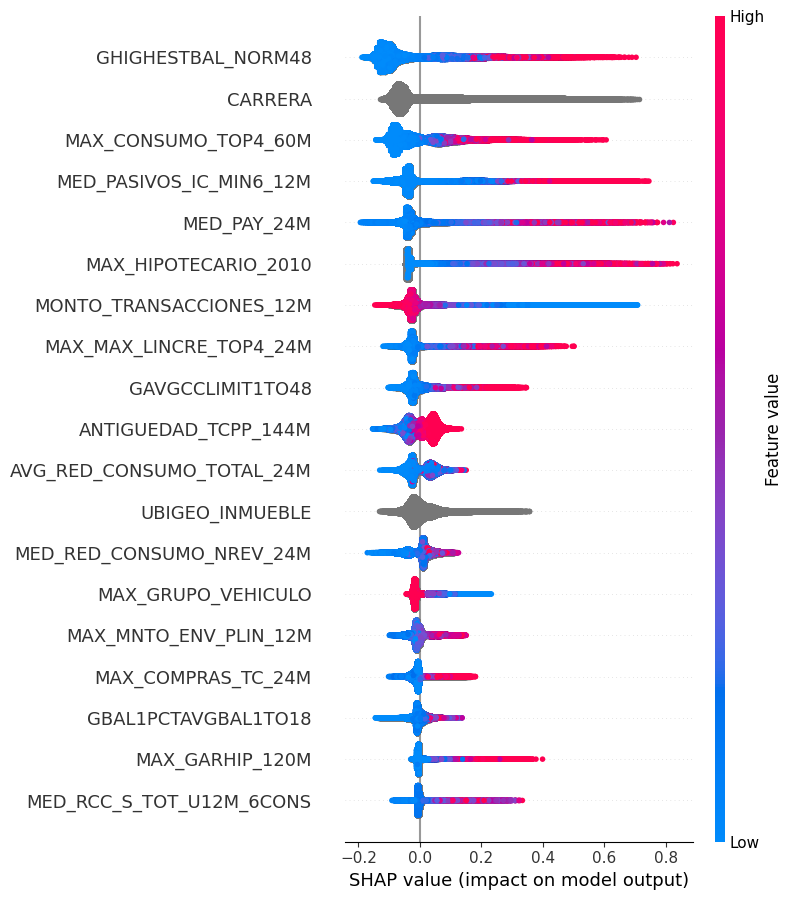

Tiempo transcurrido: 0 horas, 0 minutos y 58.433 segundos


In [221]:
with sbp.MedirTiempoEjecucion():
    shap.summary_plot(shap_exp_train, X_train)

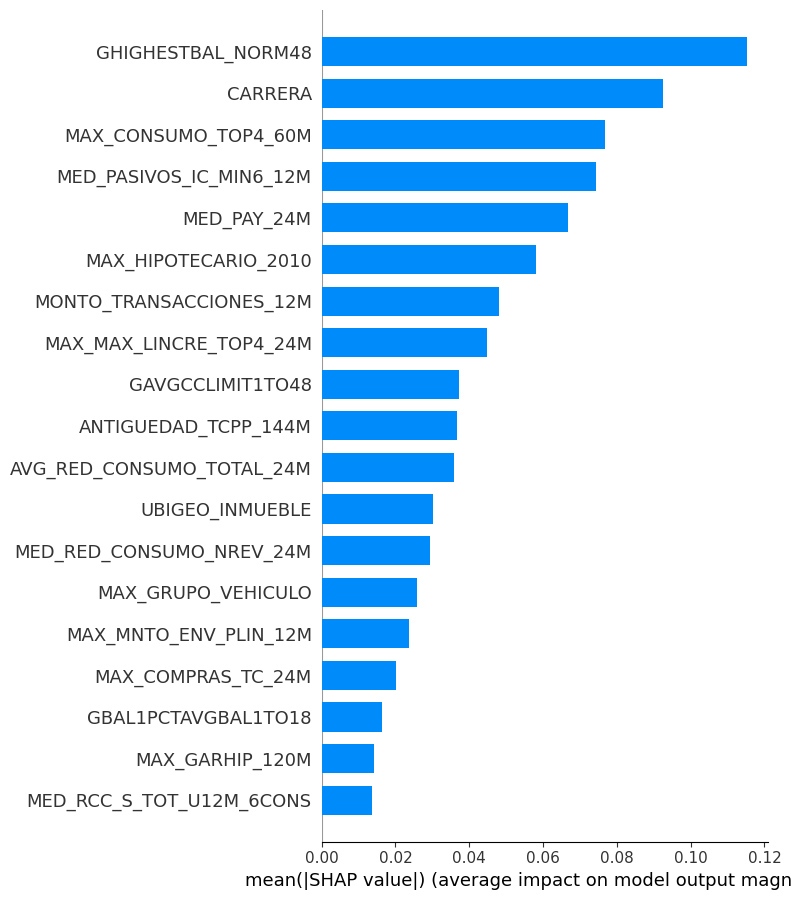

Tiempo transcurrido: 0 horas, 0 minutos y 1.138 segundos


In [222]:
with sbp.MedirTiempoEjecucion():
    shap.summary_plot(shap_exp_train, X_train, plot_type="bar")

TEST

In [60]:
with sbp.MedirTiempoEjecucion():
    shap_exp_test = explainer(X_test)

Tiempo transcurrido: 0 horas, 4 minutos y 11.336 segundos


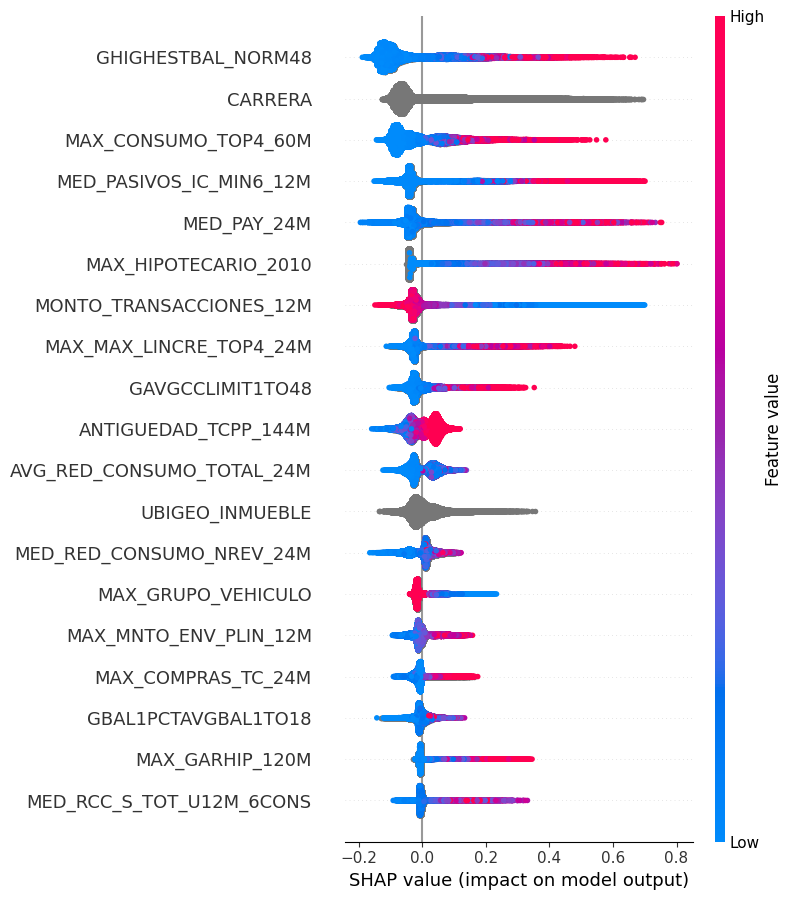

Tiempo transcurrido: 0 horas, 0 minutos y 17.264 segundos


In [224]:
with sbp.MedirTiempoEjecucion():
    shap.summary_plot(shap_exp_test, X_test)

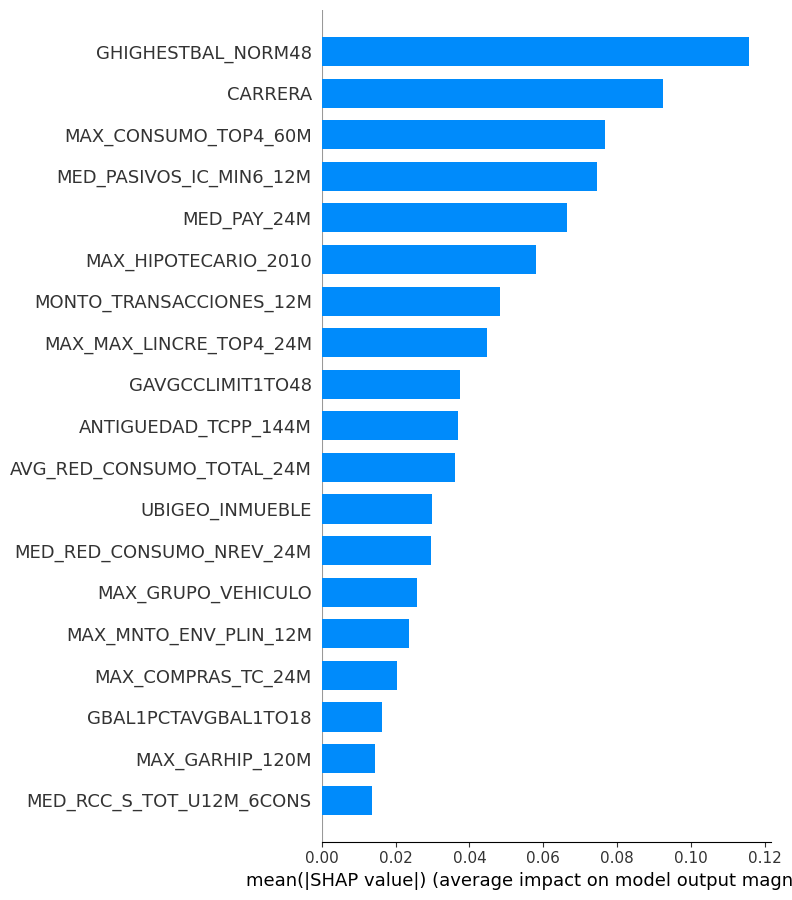

Tiempo transcurrido: 0 horas, 0 minutos y 0.520 segundos


In [225]:
with sbp.MedirTiempoEjecucion():
    shap.summary_plot(shap_exp_test, X_test, plot_type="bar")

OOT1

In [61]:
with sbp.MedirTiempoEjecucion():
    shap_exp_oot1 = explainer(X_oot1)

Tiempo transcurrido: 0 horas, 19 minutos y 29.189 segundos


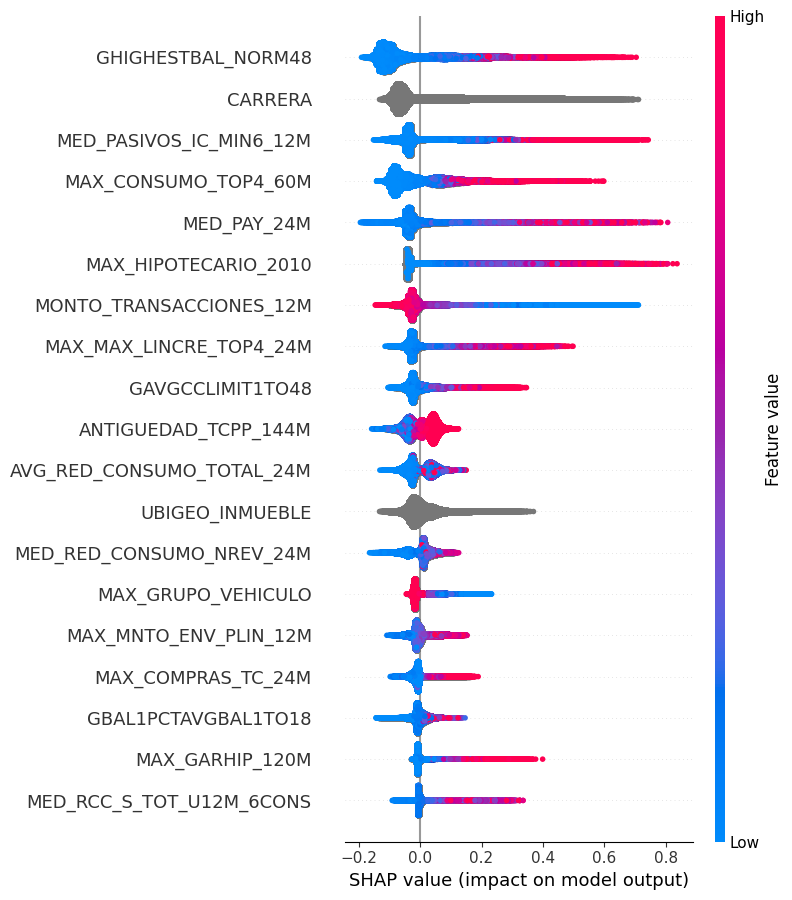

Tiempo transcurrido: 0 horas, 1 minutos y 3.343 segundos


In [227]:
with sbp.MedirTiempoEjecucion():

    shap.summary_plot(shap_exp_oot1, X_oot1)

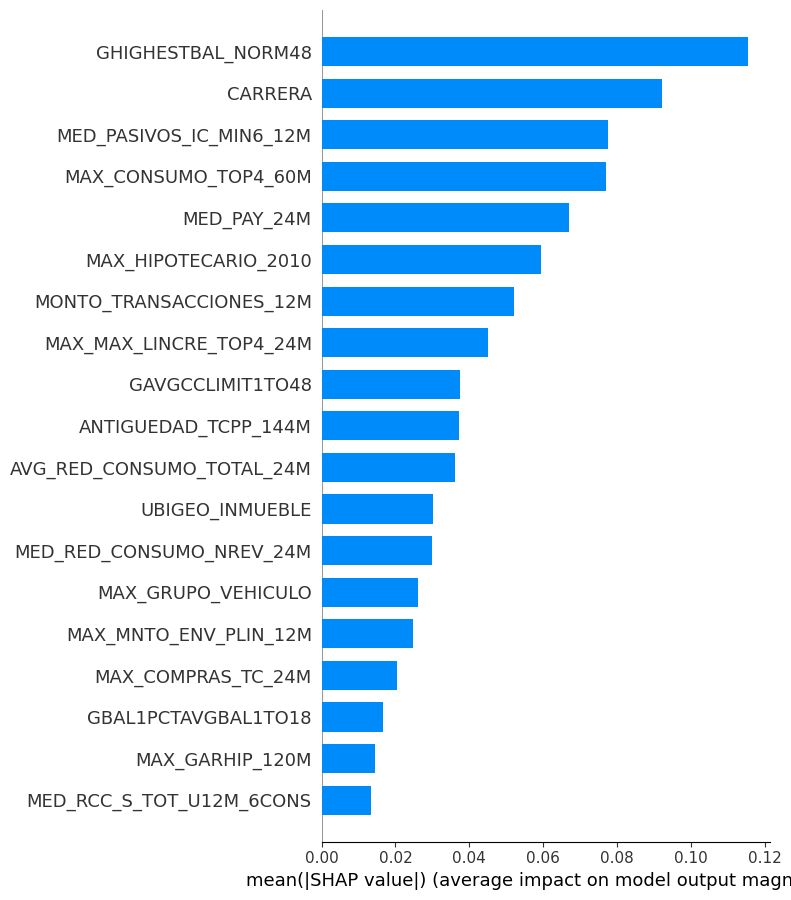

Tiempo transcurrido: 0 horas, 0 minutos y 1.398 segundos


In [228]:
with sbp.MedirTiempoEjecucion():
    shap.summary_plot(shap_exp_oot1, X_oot1, plot_type="bar")

OOT2

In [62]:
with sbp.MedirTiempoEjecucion():
    shap_exp_oot2 = explainer(X_oot2)

Tiempo transcurrido: 0 horas, 20 minutos y 2.085 segundos


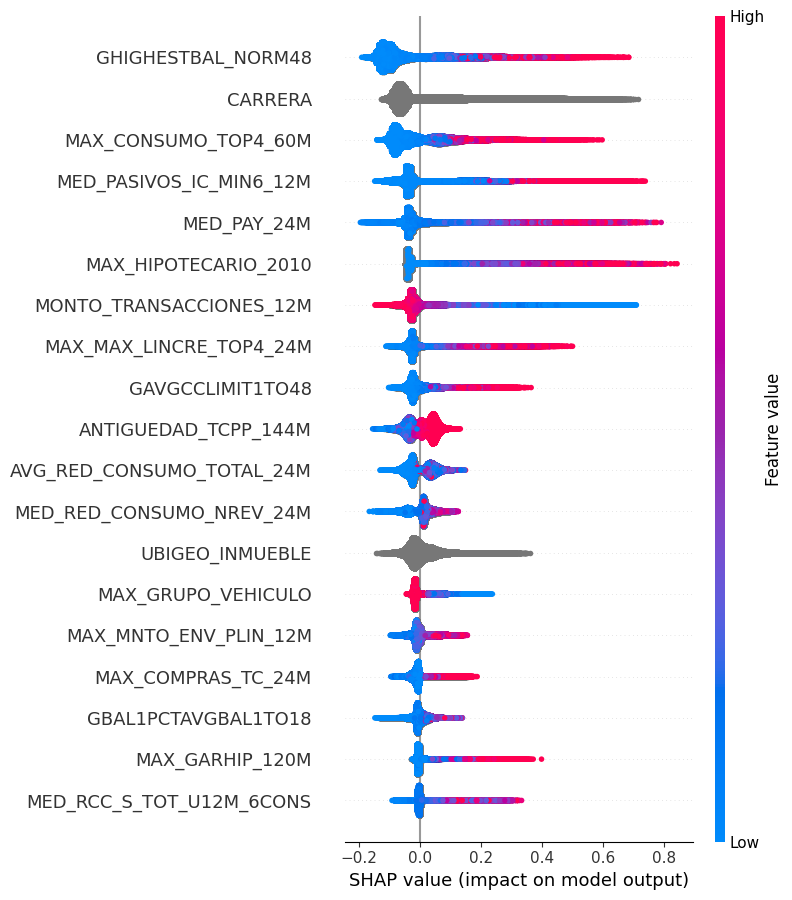

Tiempo transcurrido: 0 horas, 1 minutos y 7.082 segundos


In [230]:
with sbp.MedirTiempoEjecucion():

    shap.summary_plot(shap_exp_oot2, X_oot2)

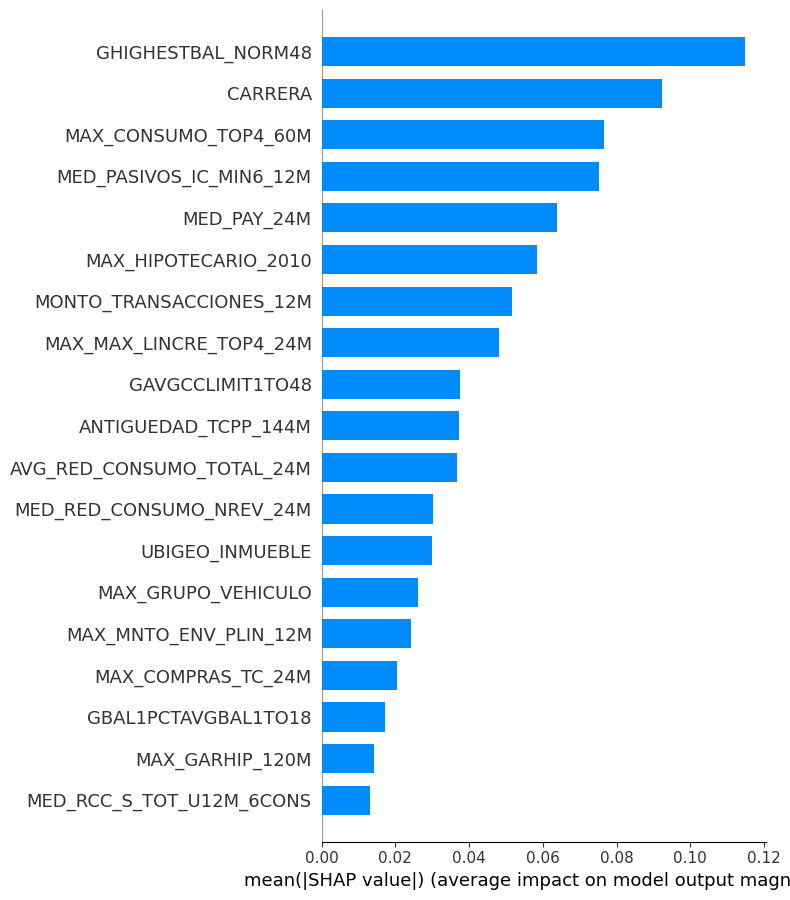

Tiempo transcurrido: 0 horas, 0 minutos y 1.398 segundos


In [231]:
with sbp.MedirTiempoEjecucion():
    shap.summary_plot(shap_exp_oot2, X_oot2, plot_type="bar")

OOT3

In [63]:
with sbp.MedirTiempoEjecucion():
    shap_exp_oot3 = explainer(X_oot3)

Tiempo transcurrido: 0 horas, 20 minutos y 20.889 segundos


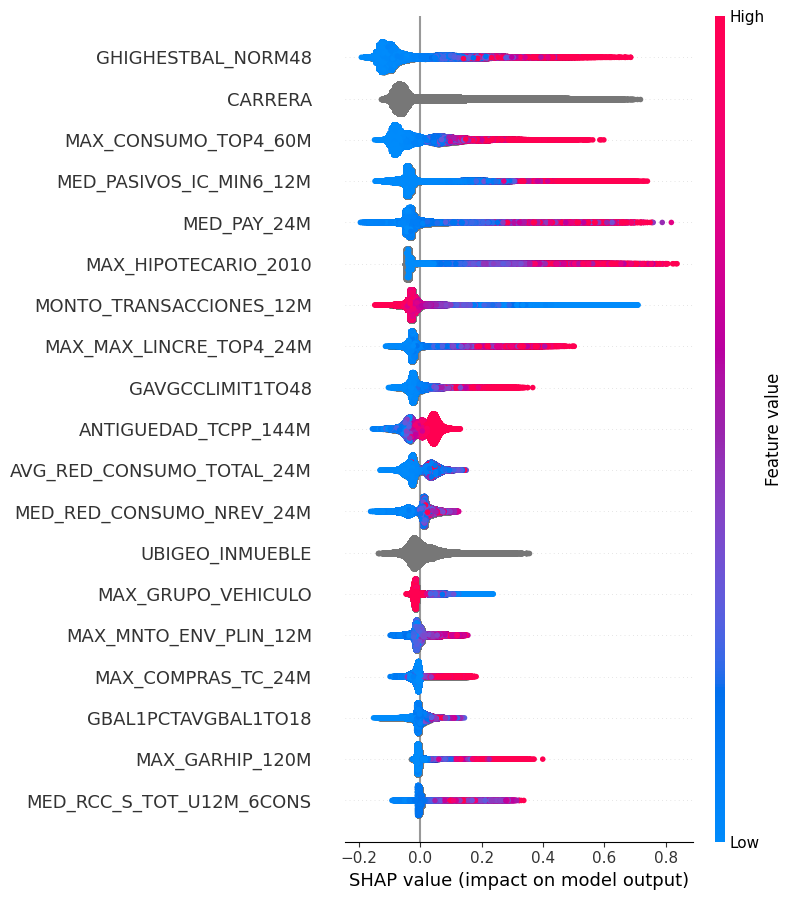

Tiempo transcurrido: 0 horas, 1 minutos y 12.672 segundos


In [233]:
with sbp.MedirTiempoEjecucion():

    shap.summary_plot(shap_exp_oot3, X_oot3)

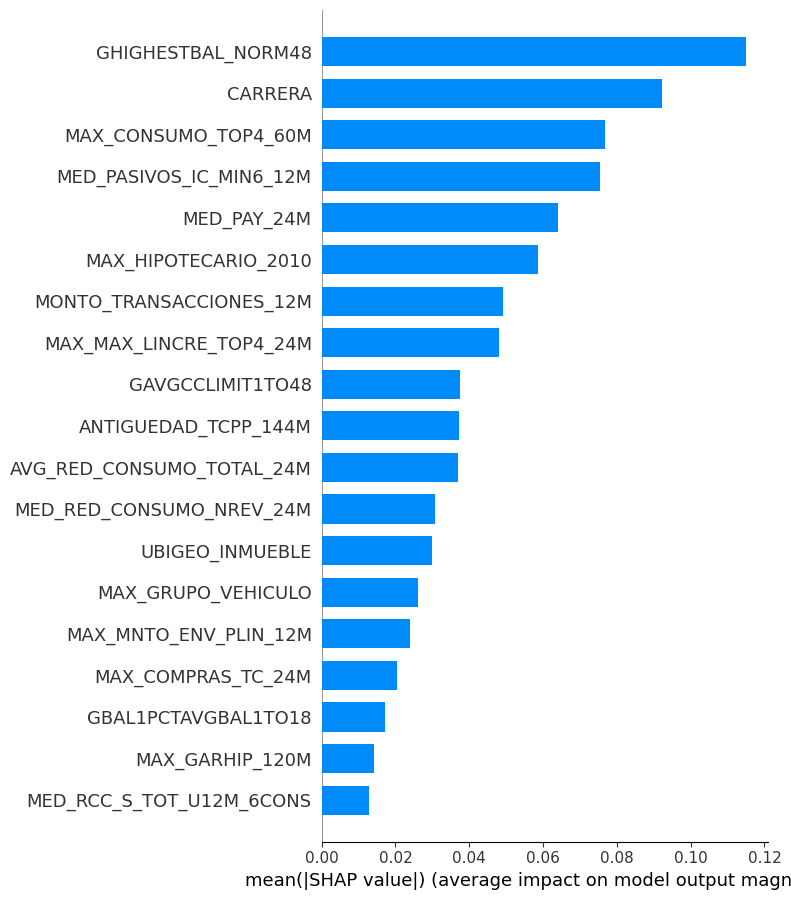

Tiempo transcurrido: 0 horas, 0 minutos y 1.706 segundos


In [234]:
with sbp.MedirTiempoEjecucion():
    shap.summary_plot(shap_exp_oot3, X_oot3, plot_type="bar")

---

#### 7.1.2.Dependence Plot

In [235]:
cols = features_rfe_best

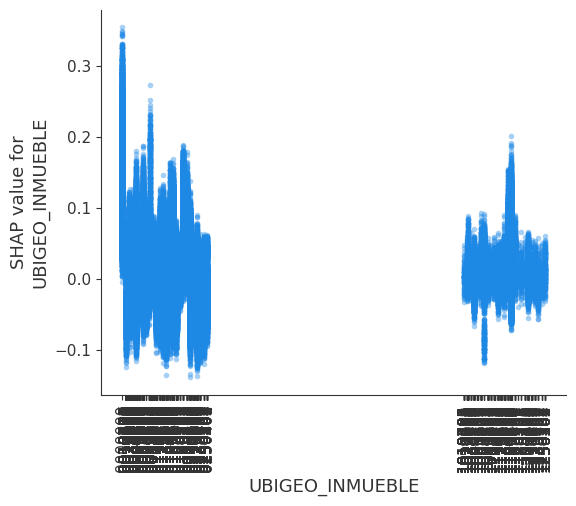

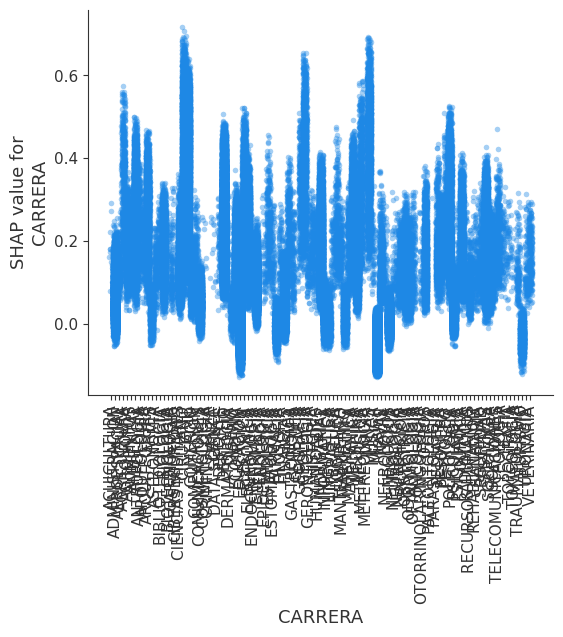

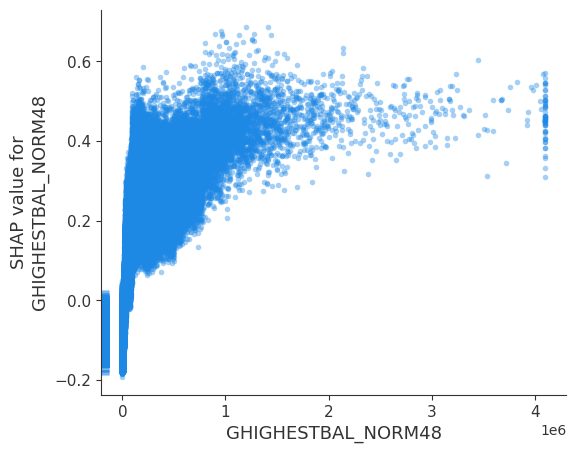

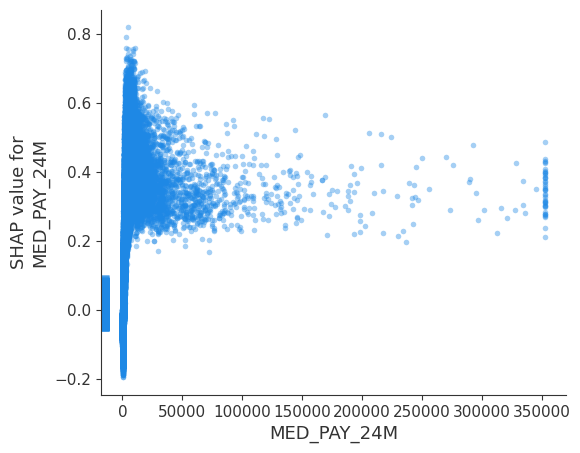

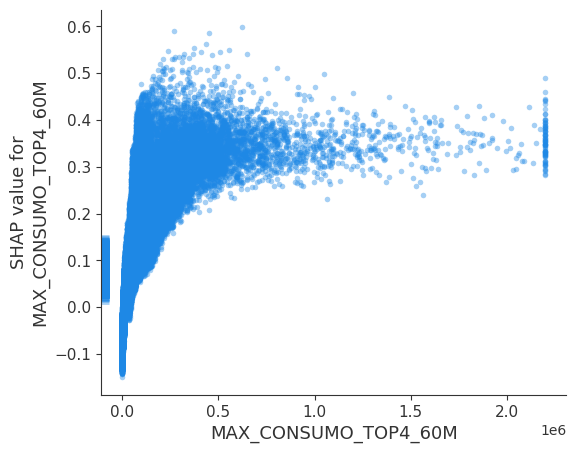

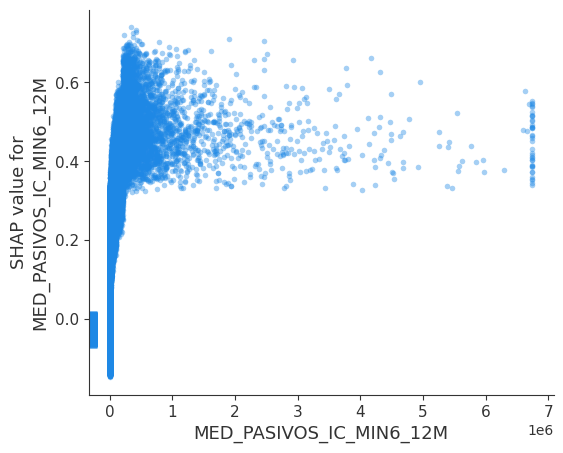

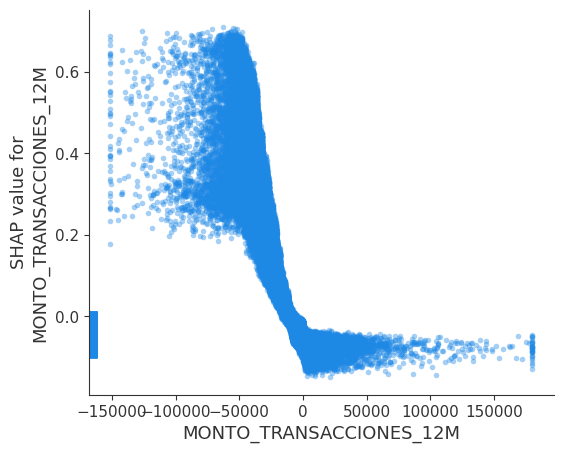

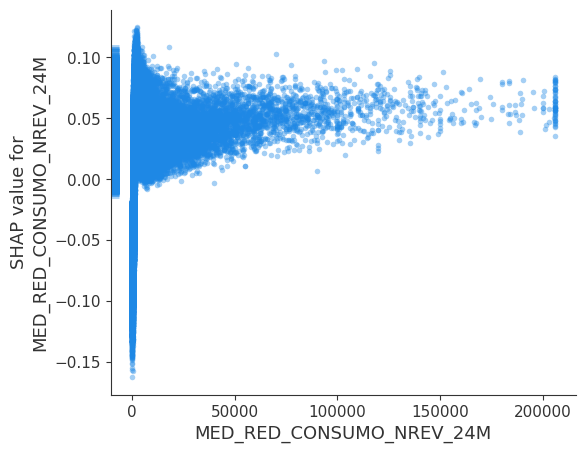

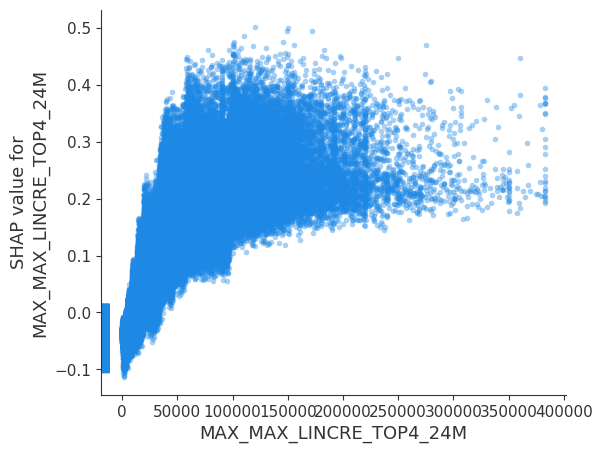

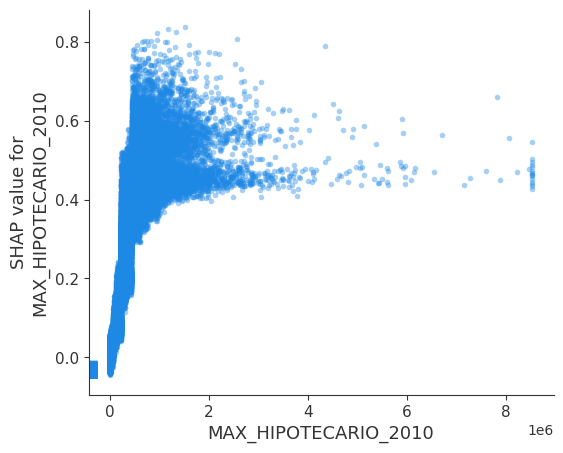

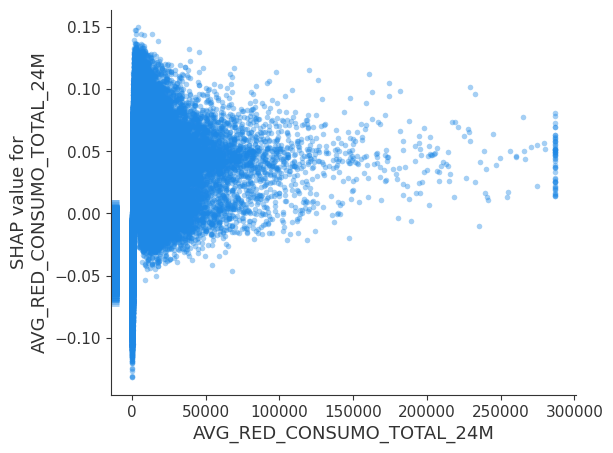

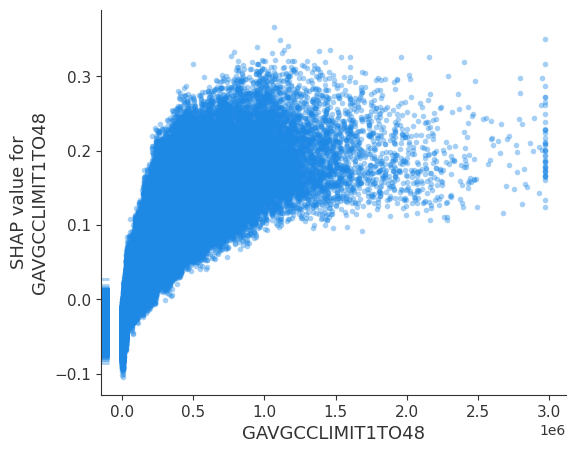

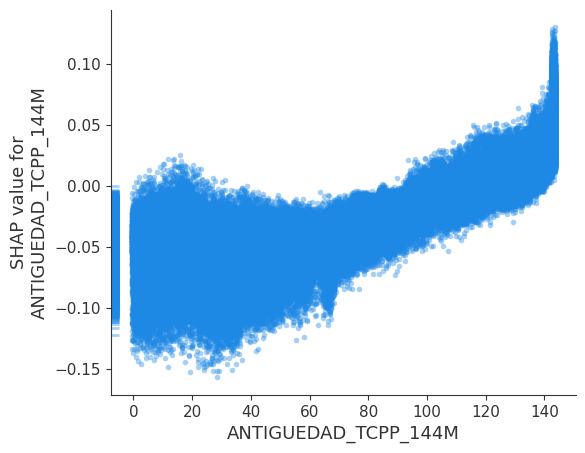

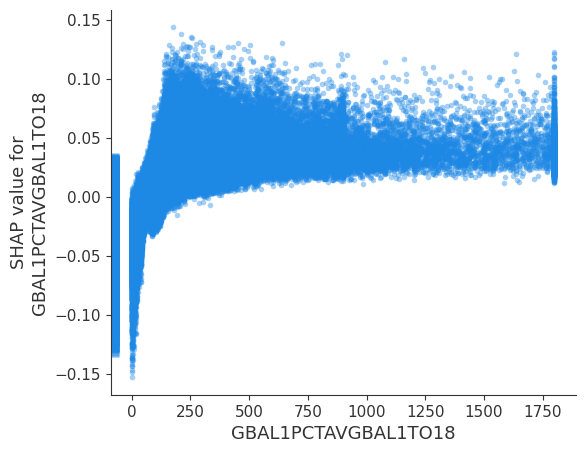

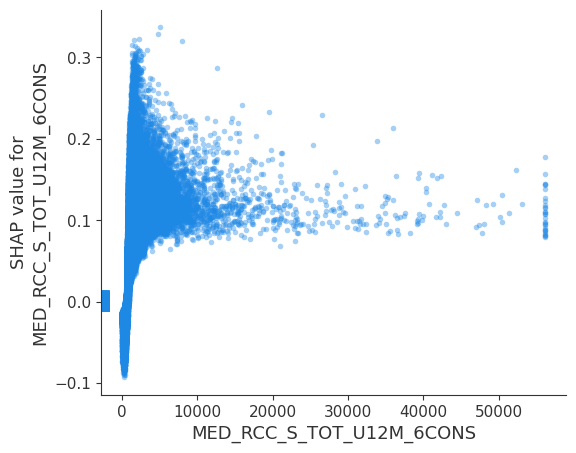

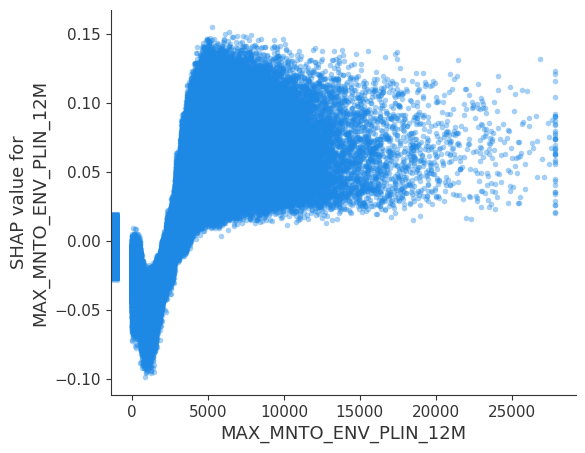

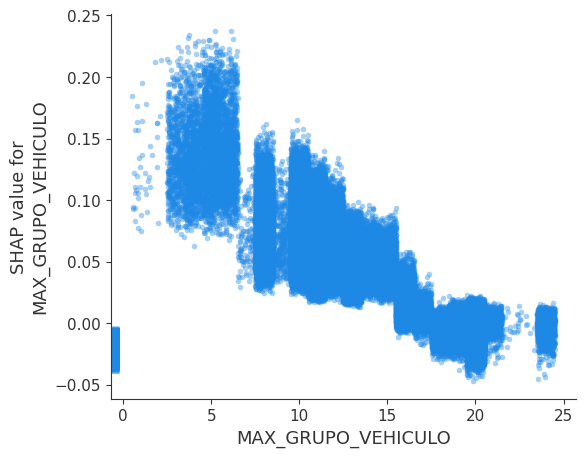

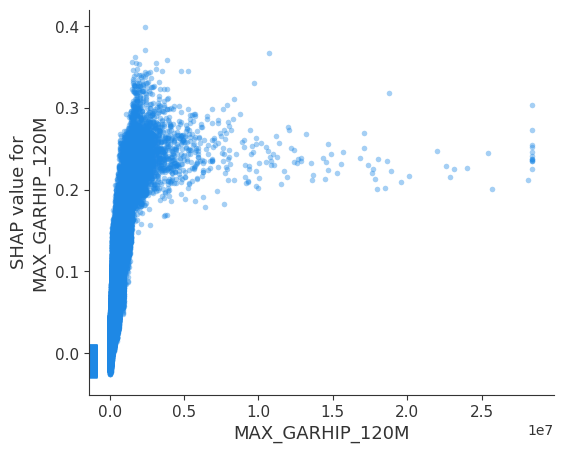

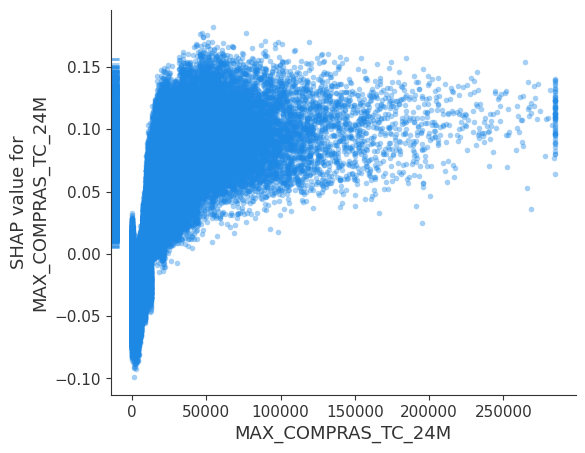

In [236]:
for i in cols:
    shap.dependence_plot(i, shap_exp_oot3.values, X_oot3,
                        interaction_index=None,alpha=0.4,show=False, 
                        x_jitter = 1)

In [177]:
base.columns

Index(['UBIGEO_INMUEBLE', 'CARRERA', 'GHIGHESTBAL_NORM48', 'MED_PAY_24M',
       'MAX_CONSUMO_TOP4_60M', 'MED_PASIVOS_IC_MIN6_12M',
       'MONTO_TRANSACCIONES_12M', 'MED_RED_CONSUMO_NREV_24M',
       'MAX_MAX_LINCRE_TOP4_24M', 'MAX_HIPOTECARIO_2010',
       'AVG_RED_CONSUMO_TOTAL_24M', 'GAVGCCLIMIT1TO48', 'ANTIGUEDAD_TCPP_144M',
       'GBAL1PCTAVGBAL1TO18', 'MED_RCC_S_TOT_U12M_6CONS',
       'MAX_MNTO_ENV_PLIN_12M', 'MAX_GRUPO_VEHICULO', 'MAX_GARHIP_120M',
       'MAX_COMPRAS_TC_24M'],
      dtype='object')

---

Filtrando outliers

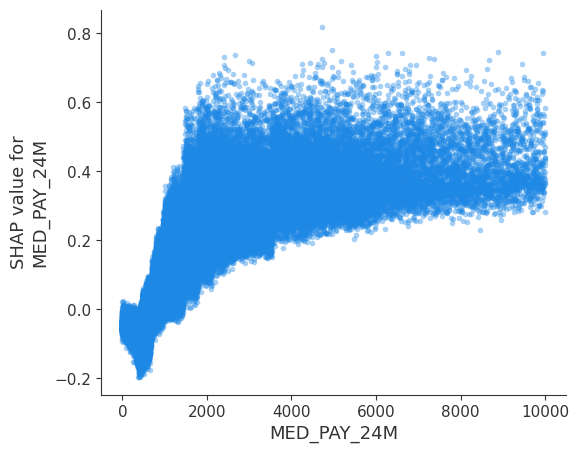

In [ ]:
base_x_var = pd.concat([base["MED_PAY_24M"],pd.DataFrame({"shap_val":shap_val[:,3]})],axis=1)
base_x_var = base_x_var.query("MED_PAY_24M<10000")

shap.dependence_plot('MED_PAY_24M', base_x_var['shap_val'], base_x_var.iloc[:, [0]],
    interaction_index=None,alpha=0.4,show=False, 
    x_jitter = 1)

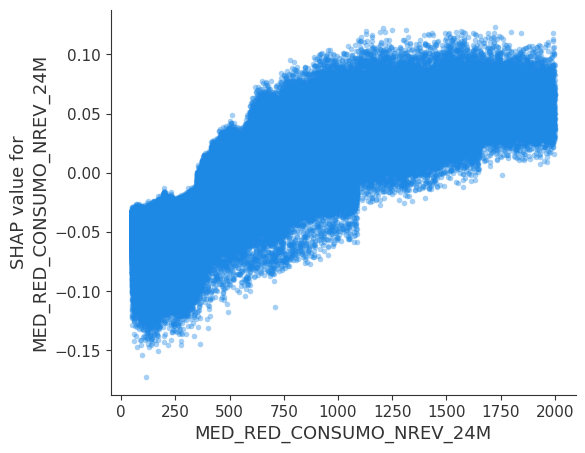

In [247]:
base_x_var = pd.concat([base["MED_RED_CONSUMO_NREV_24M"],pd.DataFrame({"shap_val":shap_val[:,7]})],axis=1)
base_x_var = base_x_var.query("MED_RED_CONSUMO_NREV_24M<2000")

shap.dependence_plot('MED_RED_CONSUMO_NREV_24M', base_x_var['shap_val'], base_x_var.iloc[:, [0]],
    interaction_index=None,alpha=0.4,show=False, 
    x_jitter = 1)

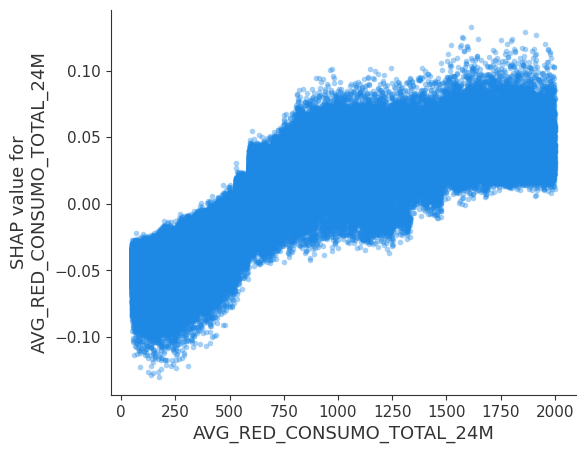

In [249]:
base_x_var = pd.concat([base["AVG_RED_CONSUMO_TOTAL_24M"],pd.DataFrame({"shap_val":shap_val[:,10]})],axis=1)
base_x_var = base_x_var.query("AVG_RED_CONSUMO_TOTAL_24M<2000")

shap.dependence_plot('AVG_RED_CONSUMO_TOTAL_24M', base_x_var['shap_val'], base_x_var.iloc[:, [0]],
    interaction_index=None,alpha=0.4,show=False, 
    x_jitter = 1)

#### 7.1.3.Importancia por rangos de ingreso

In [237]:
base2 = X_oot3

In [238]:
explainer2 = shap.TreeExplainer(gbm,feature_perturbation="tree_path_dependent")
shap_values2 = explainer2(base2)

In [239]:
shap_values2.shape

(598432, 19)

In [240]:
# Agregando y_real
shap_values2_exp= np.column_stack((shap_values2.values, y_oot3))

# Filtrando grupos
shap_values2_G1 = shap_values2_exp[(shap_values2_exp[:, shap_values2.shape[1]] <= np.log(1500))]
shap_values2_G2 = shap_values2_exp[(shap_values2_exp[:, shap_values2.shape[1]] <= np.log(2000)) & (shap_values2_exp[:, shap_values2.shape[1]] > np.log(1500))]
shap_values2_G3 = shap_values2_exp[(shap_values2_exp[:, shap_values2.shape[1]] <= np.log(3500)) & (shap_values2_exp[:, shap_values2.shape[1]] > np.log(2000))]
shap_values2_G4 = shap_values2_exp[(shap_values2_exp[:, shap_values2.shape[1]] <= np.log(5000)) & (shap_values2_exp[:, shap_values2.shape[1]] > np.log(3500))]
shap_values2_G5 = shap_values2_exp[(shap_values2_exp[:, shap_values2.shape[1]] <= np.log(7000)) & (shap_values2_exp[:, shap_values2.shape[1]] > np.log(5000))]
shap_values2_G6 = shap_values2_exp[(shap_values2_exp[:, shap_values2.shape[1]] <= np.log(10000)) & (shap_values2_exp[:, shap_values2.shape[1]] > np.log(7000))]
shap_values2_G7 = shap_values2_exp[(shap_values2_exp[:, shap_values2.shape[1]] <= np.log(12500)) & (shap_values2_exp[:, shap_values2.shape[1]] > np.log(10000))]
shap_values2_G8 = shap_values2_exp[(shap_values2_exp[:, shap_values2.shape[1]] <= np.log(15000)) & (shap_values2_exp[:, shap_values2.shape[1]] > np.log(12500))]
shap_values2_G9 = shap_values2_exp[(shap_values2_exp[:, shap_values2.shape[1]] > np.log(15000))]

# Quitando y_real
for i in range(1, 10):
    exec(f"shap_values2_G{i} = shap_values2_G{i}[:, :-1]")

valor esperado

In [241]:
explainer2.expected_value

7.788703069217836

In [242]:
shap_summary = {}

for i in range(1, 10):

    shap_values_group = eval(f"shap_values2_G{i}")  
    mean_abs_shap_values = np.abs(shap_values_group).mean(axis=0)    
    shap_summary[f"G{i}"] = mean_abs_shap_values

feature_names = shap_values2.feature_names
shap_df = pd.DataFrame(shap_summary, index=feature_names)

shap_df

,G1,G2,G3,G4,G5,G6,G7,G8,G9
UBIGEO_INMUEBLE,0.027316,0.027893,0.029138,0.030664,0.031988,0.034142,0.038285,0.041673,0.052434
CARRERA,0.075024,0.076242,0.090060,0.113297,0.129671,0.123785,0.109453,0.099446,0.077060
GHIGHESTBAL_NORM48,0.112657,0.105858,0.098033,0.108026,0.127640,0.153587,0.181524,0.203129,0.259511
MED_PAY_24M,0.040223,0.039170,0.047309,0.067922,0.103942,0.139787,0.170204,0.192333,0.235870
MAX_CONSUMO_TOP4_60M,0.068654,0.065516,0.069488,0.077977,0.089106,0.105662,0.122465,0.132670,0.165291
MED_PASIVOS_IC_MIN6_12M,0.056939,0.060624,0.070673,0.088306,0.099728,0.110130,0.116575,0.120651,0.142961
MONTO_TRANSACCIONES_12M,0.035041,0.040064,0.051505,0.065286,0.064342,0.061326,0.059100,0.053395,0.045774
MED_RED_CONSUMO_NREV_24M,0.026082,0.027177,0.029299,0.033975,0.036624,0.039357,0.040878,0.042728,0.048445
MAX_MAX_LINCRE_TOP4_24M,0.030705,0.032119,0.038569,0.052821,0.073973,0.095720,0.117792,0.126146,0.153028
MAX_HIPOTECARIO_2010,0.038558,0.038382,0.039052,0.051719,0.085348,0.133909,0.182354,0.212490,0.269514
